In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from pandas import DataFrame
from scipy.stats import mannwhitneyu
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.statistics import logrank_test, multivariate_logrank_test
from lifelines.utils import concordance_index

In [ ]:
# Paths are relative to the project folder: inputs in data/, files written by
# earlier notebooks in results/, figures in figures/.
DATA_DIR = 'data'
RESULTS_DIR = 'results'
FIGURE_DIR = 'figures'

# Input files
TRANSCELL_RESULTS = f'{DATA_DIR}/ALLDECONVALID_results.csv'
DRUG_AUC = f'{DATA_DIR}/beataml2_patients_drug.csv'
CLINICAL = f'{DATA_DIR}/beataml2_data.csv'

In [3]:
total_df = pd.read_csv(TRANSCELL_RESULTS, index_col=0)
clin = pd.read_csv(CLINICAL, low_memory=False)

In [4]:
# cohort: de novo, RNA-seq, specimen at inclusion, 7+3-type induction (anthracycline + cytarabine)
clin = clin[(clin['rnaSeq'] == 'y') & (clin['isDenovo'].astype(str).str.upper() == 'TRUE')
            & (clin['timeOfSampleCollectionRelativeToInclusion'] == 0)
            & (clin['typeInductionTx'] == 'Standard Chemotherapy')]
clin = clin[clin['cumulativeTreatmentRegimens'].str.split('|').str[0].str.contains(r'^(?:7\+3|5\+2|3\+7)', na=False)]
clin = clin[clin['vitalStatus'].isin(['Dead', 'Alive']) & (clin['overallSurvival'] > 0)]
clin = clin.drop_duplicates('dbgap_subject_id').set_index('dbgap_subject_id')

clin['E'] = (clin['vitalStatus'] == 'Dead').astype(int)
clin['eln'] = clin['ELN2017'].map({'Favorable': 0, 'Intermediate': 1, 'Adverse': 2})
clin['remission'] = clin['responseToInductionTx'].map({
    'Complete Response': 'Remission', 'Complete Response i': 'Remission', 'Refractory': 'Refractory'})
clin['blast'] = pd.to_numeric(clin['%.Blasts.in.BM'], errors='coerce')
clin['blast_group'] = pd.Series(index=clin.index, dtype='object')
clin.loc[clin['blast'] < 50, 'blast_group'] = 'low blast (<50%)'
clin.loc[clin['blast'] > 50, 'blast_group'] = 'high blast (>50%)'

cohort = clin[['overallSurvival', 'E', 'ageAtDiagnosis', 'eln', 'remission', 'vitalStatus', 'blast_group']]
print(cohort.shape, 'dead', int(cohort.E.sum()), 'alive', int((cohort.E == 0).sum()),
      'remission', int((cohort.remission == 'Remission').sum()),
      'refractory', int((cohort.remission == 'Refractory').sum()))
print(cohort['blast_group'].value_counts(dropna=False).to_dict())

(130, 7) dead 61 alive 69 remission 84 refractory 33
{'high blast (>50%)': 84, 'low blast (<50%)': 27, nan: 19}


In [5]:
list_refs = ['P38', 'P14', 'P30', 'P23', 'P34', 'P25', 'P20', 'P36']
drugs = ['cytarabine', 'daunorubicin', 'idarubicin', 'venetoclax', 'azacitidine']

scores = {}
for drug in drugs:
    one = total_df.loc[drug]
    wide = DataFrame({'ref': one.index.str.split('_').str[0],
                      'pid': one.index.str.split('_').str[1].astype(int),
                      'v': one.values}).pivot_table(index='pid', columns='ref', values='v')
    scores[drug] = wide.reindex(columns=['Bulk'] + list_refs).reindex(cohort.index)
    print(drug, scores[drug].notna().sum().to_dict())

cytarabine {'Bulk': 78, 'P38': 78, 'P14': 78, 'P30': 78, 'P23': 78, 'P34': 78, 'P25': 78, 'P20': 78, 'P36': 78}
daunorubicin {'Bulk': 78, 'P38': 78, 'P14': 78, 'P30': 78, 'P23': 78, 'P34': 78, 'P25': 78, 'P20': 78, 'P36': 78}
idarubicin {'Bulk': 78, 'P38': 78, 'P14': 78, 'P30': 78, 'P23': 78, 'P34': 78, 'P25': 78, 'P20': 78, 'P36': 78}
venetoclax {'Bulk': 78, 'P38': 78, 'P14': 78, 'P30': 78, 'P23': 78, 'P34': 78, 'P25': 78, 'P20': 78, 'P36': 78}
azacitidine {'Bulk': 78, 'P38': 78, 'P14': 78, 'P30': 78, 'P23': 78, 'P34': 78, 'P25': 78, 'P20': 78, 'P36': 78}


In [6]:
# alive vs dead: a small p means the score is higher in patients who died
# (lower score goes with still being alive)
rows = []
for drug in drugs:
    for m in scores[drug].columns:
        d = cohort[['E']].join(scores[drug][m].rename('score')).dropna()
        u, p = mannwhitneyu(d[d.E == 1].score, d[d.E == 0].score, alternative='greater')
        rows.append([drug, m, len(d), int((d.E == 1).sum()), int((d.E == 0).sum()),
                     d[d.E == 1].score.median(), d[d.E == 0].score.median(), p])
alive_df = DataFrame(rows, columns=['drug', 'method', 'n', 'n_dead', 'n_alive', 'median_dead', 'median_alive', 'p_dead_higher'])
alive_df.round(3)

,drug,method,n,n_dead,n_alive,median_dead,median_alive,p_dead_higher
0,cytarabine,Bulk,78,35,43,0.398,0.513,0.848
1,cytarabine,P38,78,35,43,0.000,-0.162,0.215
2,cytarabine,P14,78,35,43,-0.003,0.000,0.655
3,cytarabine,P30,78,35,43,0.123,0.200,0.877
4,cytarabine,P23,78,35,43,-0.279,-0.300,0.570
5,cytarabine,P34,78,35,43,-0.801,-0.797,0.892
6,cytarabine,P25,78,35,43,-0.243,-0.308,0.087
7,cytarabine,P20,78,35,43,0.597,0.597,0.639
8,cytarabine,P36,78,35,43,0.307,0.314,0.619
9,daunorubicin,Bulk,78,35,43,-1.846,-1.823,0.682


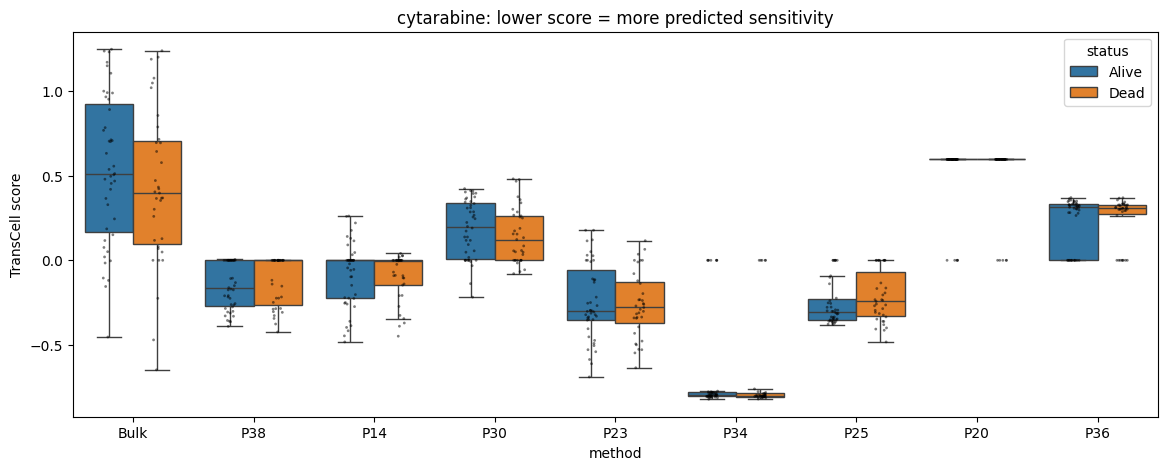

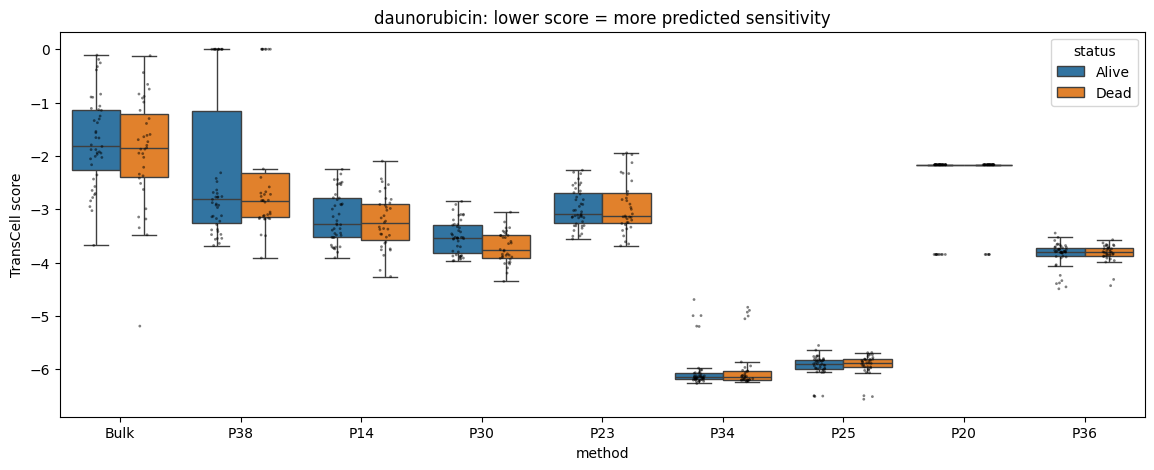

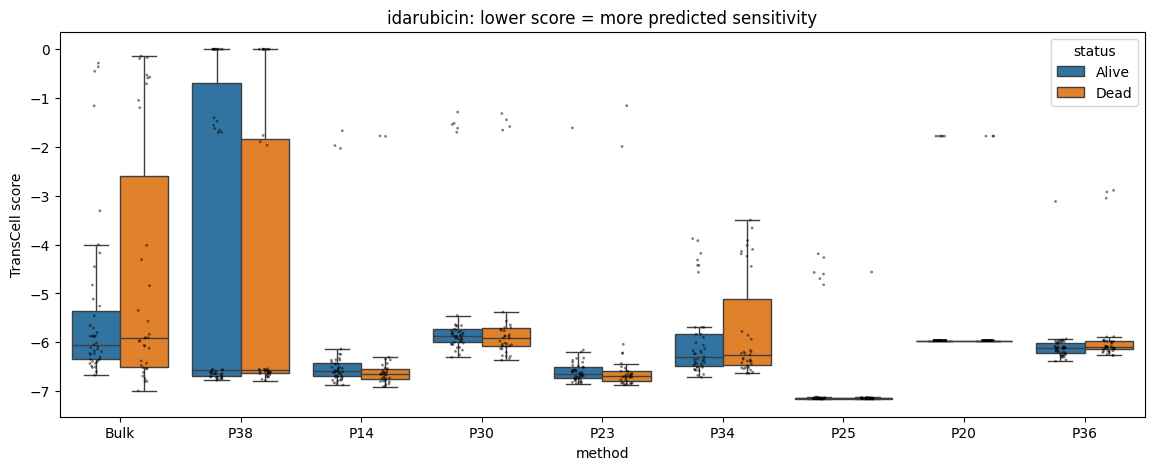

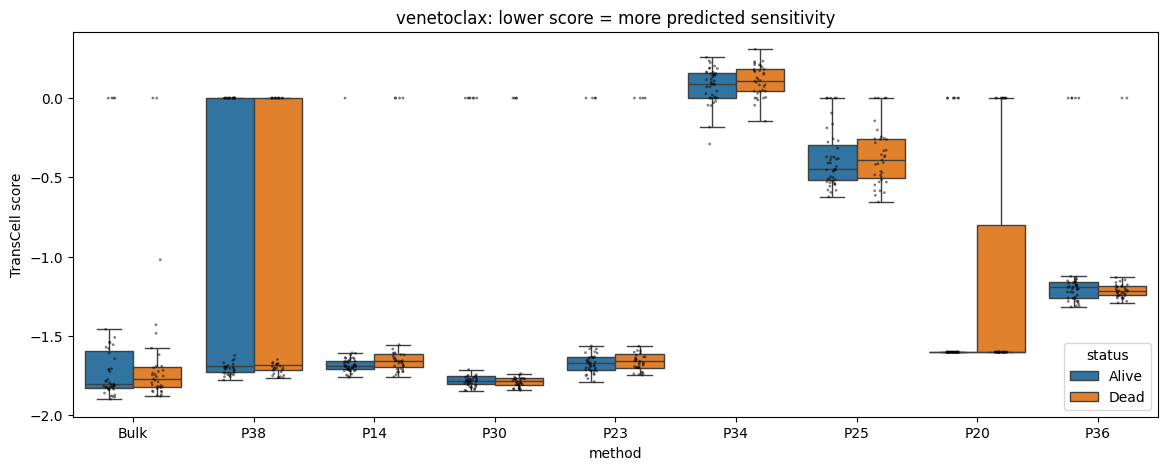

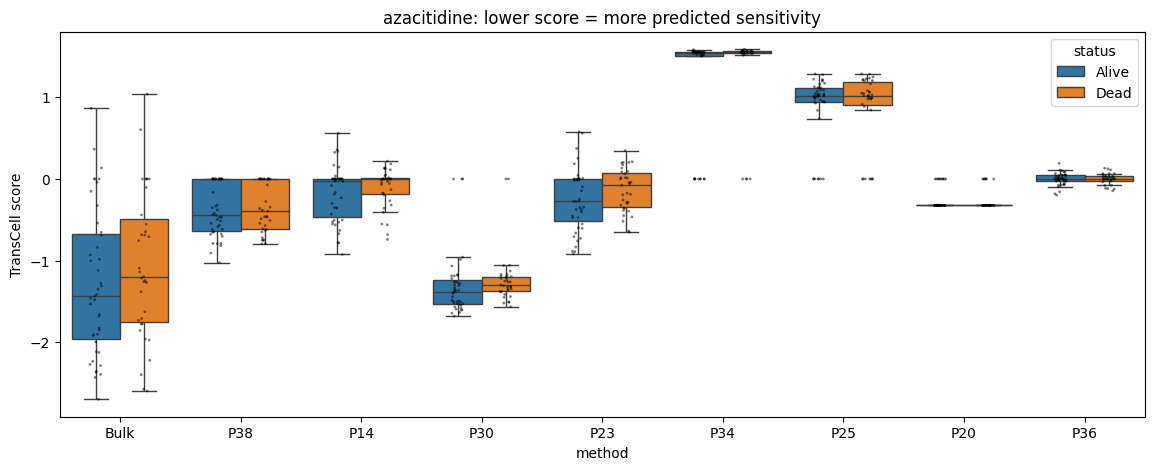

In [7]:
for drug in drugs:
    data = pd.concat([
        cohort[['E']].join(scores[drug][m].rename('score')).dropna().assign(method=m)
        for m in scores[drug].columns
    ])
    data['status'] = data['E'].map({1: 'Dead', 0: 'Alive'})
    plt.figure(figsize=(14, 5))
    sns.boxplot(data=data, x='method', y='score', hue='status', hue_order=['Alive', 'Dead'], showfliers=False)
    sns.stripplot(data=data, x='method', y='score', hue='status', hue_order=['Alive', 'Dead'],
                  dodge=True, palette={'Alive': 'black', 'Dead': 'black'}, size=2, alpha=0.5, legend=False)
    plt.ylabel('TransCell score')
    plt.title(drug + ': lower score = more predicted sensitivity')
    plt.show()

In [8]:
# remission vs refractory: a small p means the score is higher in refractory patients
rows = []
for drug in drugs:
    for m in scores[drug].columns:
        d = cohort[['remission']].join(scores[drug][m].rename('score')).dropna()
        hi = d[d.remission == 'Refractory'].score
        lo = d[d.remission == 'Remission'].score
        u, p = mannwhitneyu(hi, lo, alternative='greater')
        rows.append([drug, m, len(d), len(lo), len(hi), lo.median(), hi.median(), p])
rem_df = DataFrame(rows, columns=['drug', 'method', 'n', 'n_remission', 'n_refractory', 'median_remission', 'median_refractory', 'p_refractory_higher'])
rem_df.round(3)

,drug,method,n,n_remission,n_refractory,median_remission,median_refractory,p_refractory_higher
0,cytarabine,Bulk,78,56,22,0.488,0.414,0.731
1,cytarabine,P38,78,56,22,-0.136,-0.059,0.259
2,cytarabine,P14,78,56,22,-0.033,0.000,0.328
3,cytarabine,P30,78,56,22,0.164,0.156,0.369
4,cytarabine,P23,78,56,22,-0.308,-0.246,0.074
5,cytarabine,P34,78,56,22,-0.800,-0.800,0.694
6,cytarabine,P25,78,56,22,-0.298,-0.228,0.194
7,cytarabine,P20,78,56,22,0.597,0.597,0.814
8,cytarabine,P36,78,56,22,0.310,0.310,0.782
9,daunorubicin,Bulk,78,56,22,-1.715,-2.120,0.941


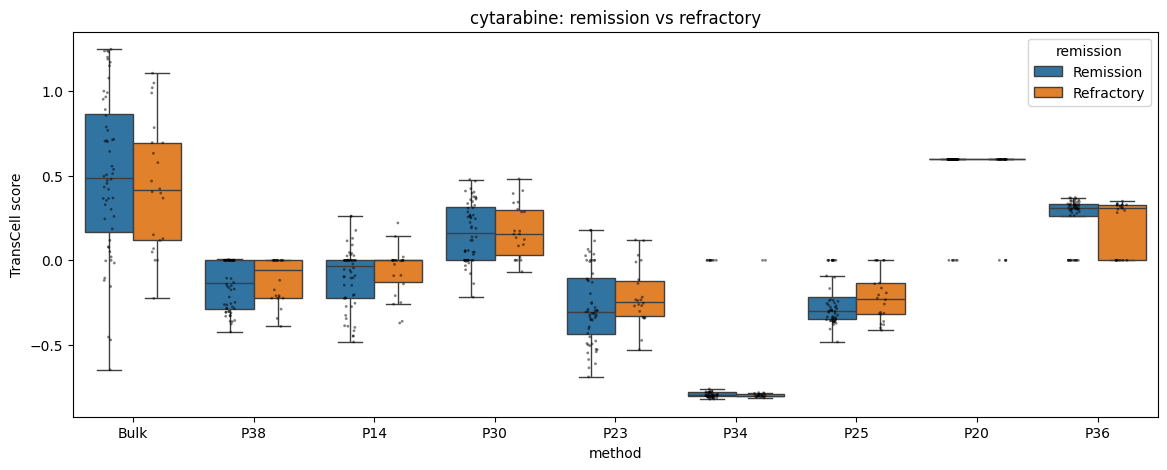

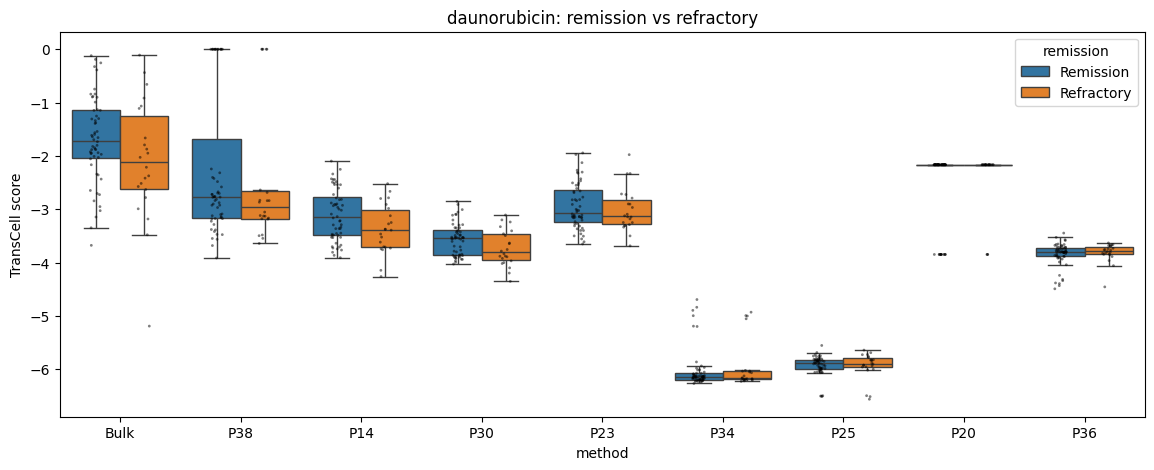

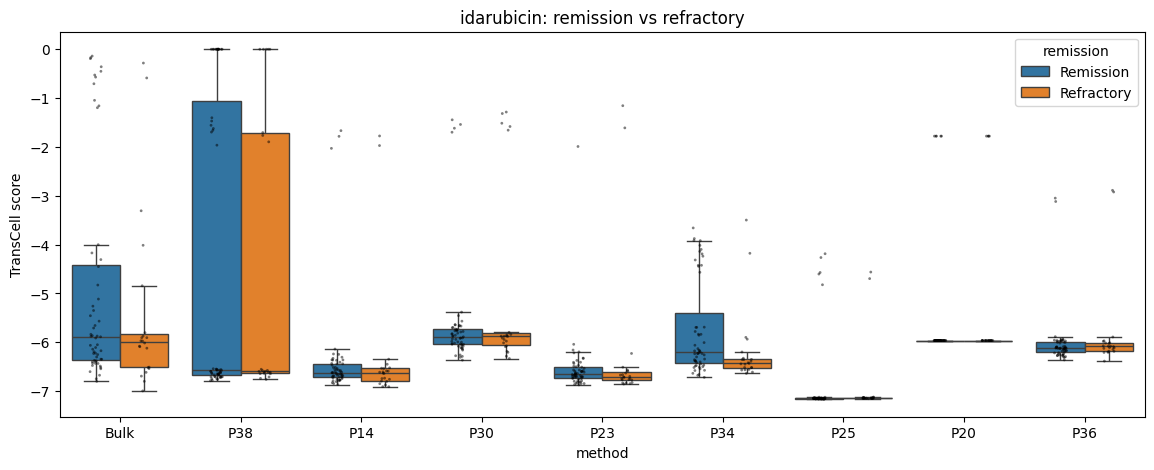

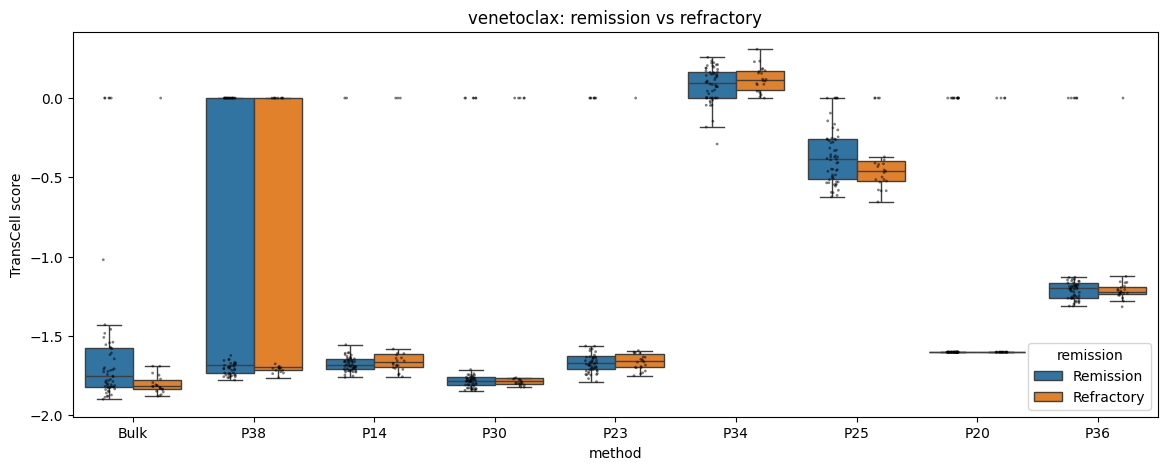

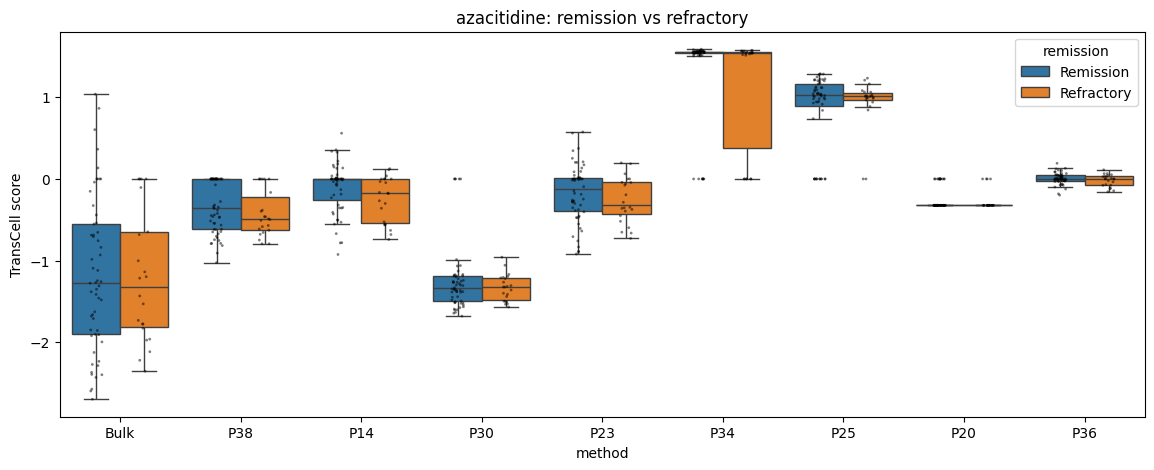

In [9]:
for drug in drugs:
    data = pd.concat([
        cohort[['remission']].join(scores[drug][m].rename('score')).dropna().assign(method=m)
        for m in scores[drug].columns
    ])
    plt.figure(figsize=(14, 5))
    sns.boxplot(data=data, x='method', y='score', hue='remission', hue_order=['Remission', 'Refractory'], showfliers=False)
    sns.stripplot(data=data, x='method', y='score', hue='remission', hue_order=['Remission', 'Refractory'],
                  dodge=True, palette={'Remission': 'black', 'Refractory': 'black'}, size=2, alpha=0.5, legend=False)
    plt.ylabel('TransCell score')
    plt.title(drug + ': remission vs refractory')
    plt.show()

In [10]:
# overall survival: Cox HR per 1 SD of the raw score, adjusted for age and ELN2017
# HR above 1 means a higher score (less predicted sensitivity) goes with a higher risk of death
rows = []
for drug in drugs:
    for m in scores[drug].columns:
        d = cohort.join(scores[drug][m].rename('score')).dropna(subset=['score', 'ageAtDiagnosis', 'eln']).copy()
        d['z'] = (d.score - d.score.mean()) / d.score.std()
        cph = CoxPHFitter().fit(d[['overallSurvival', 'E', 'z', 'ageAtDiagnosis', 'eln']], 'overallSurvival', 'E')
        s = cph.summary.loc['z']
        c = concordance_index(d.overallSurvival, -d.score, d.E)
        rows.append([drug, m, len(d), int(d.E.sum()), s['exp(coef)'], s['exp(coef) lower 95%'], s['exp(coef) upper 95%'], s['p'], c])
cox_df = DataFrame(rows, columns=['drug', 'method', 'n', 'events', 'HR_per_SD', 'lo', 'hi', 'p', 'C_lower_score_longer_life'])
cox_df.round(3)

,drug,method,n,events,HR_per_SD,lo,hi,p,C_lower_score_longer_life
0,cytarabine,Bulk,73,32,0.754,0.518,1.098,0.141,0.434
1,cytarabine,P38,73,32,0.887,0.615,1.279,0.520,0.531
2,cytarabine,P14,73,32,1.025,0.707,1.487,0.897,0.505
3,cytarabine,P30,73,32,0.985,0.664,1.462,0.940,0.441
4,cytarabine,P23,73,32,0.855,0.583,1.253,0.422,0.465
5,cytarabine,P34,73,32,1.074,0.737,1.563,0.711,0.449
6,cytarabine,P25,73,32,1.235,0.880,1.734,0.223,0.578
7,cytarabine,P20,73,32,0.882,0.626,1.242,0.472,0.485
8,cytarabine,P36,73,32,1.098,0.758,1.590,0.622,0.471
9,daunorubicin,Bulk,73,32,0.759,0.546,1.055,0.101,0.398


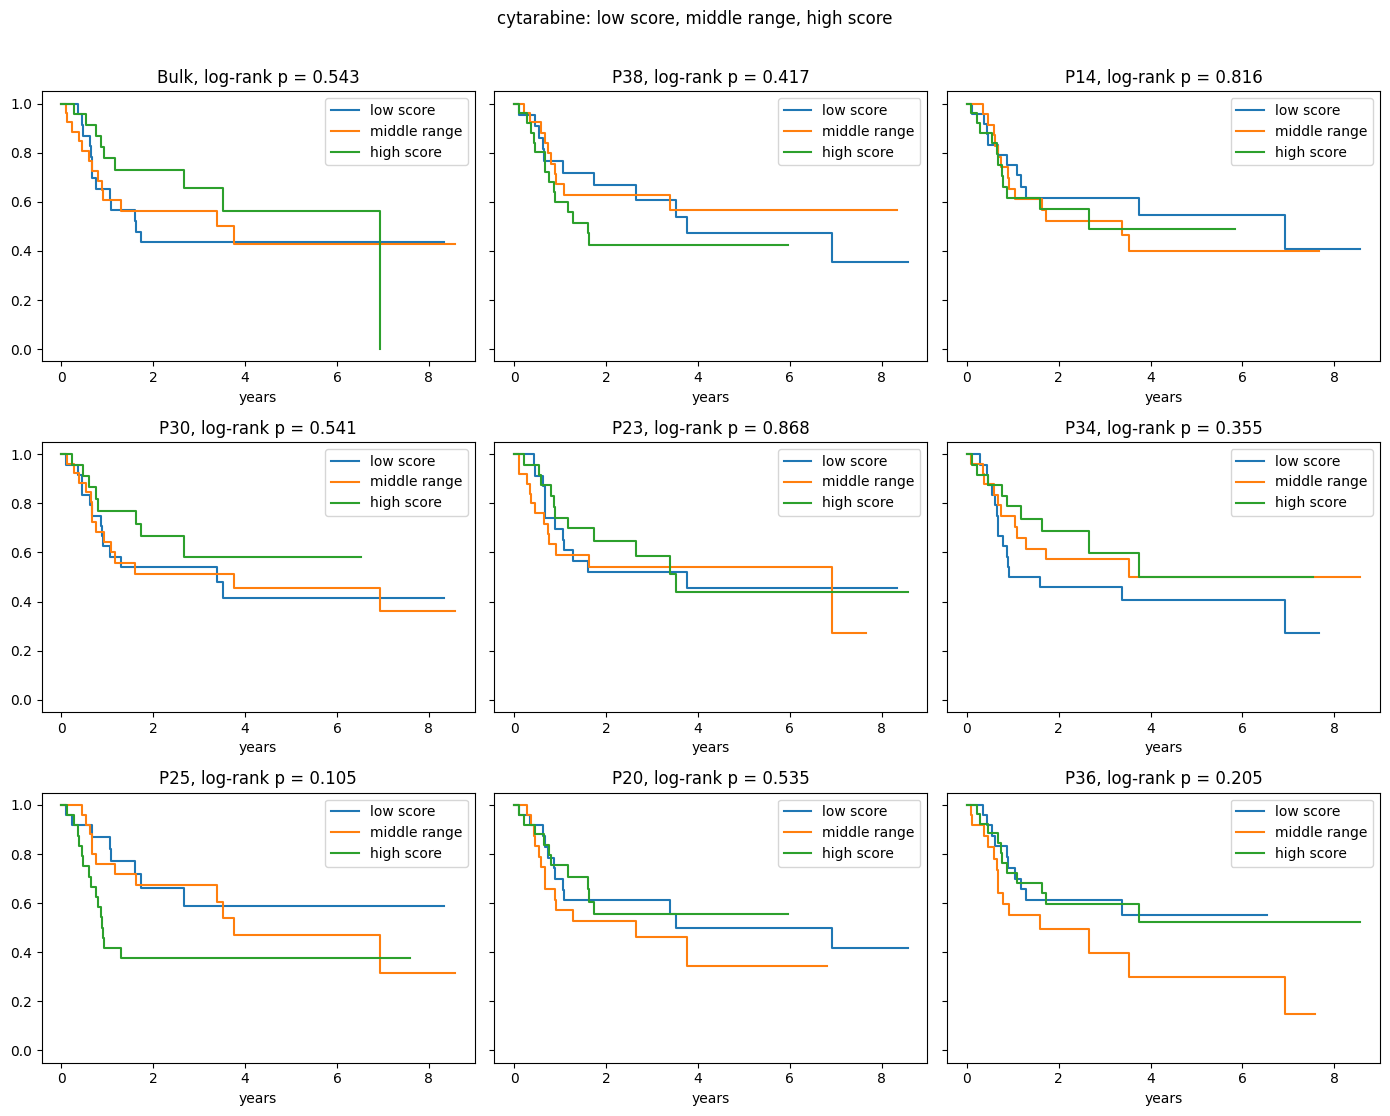

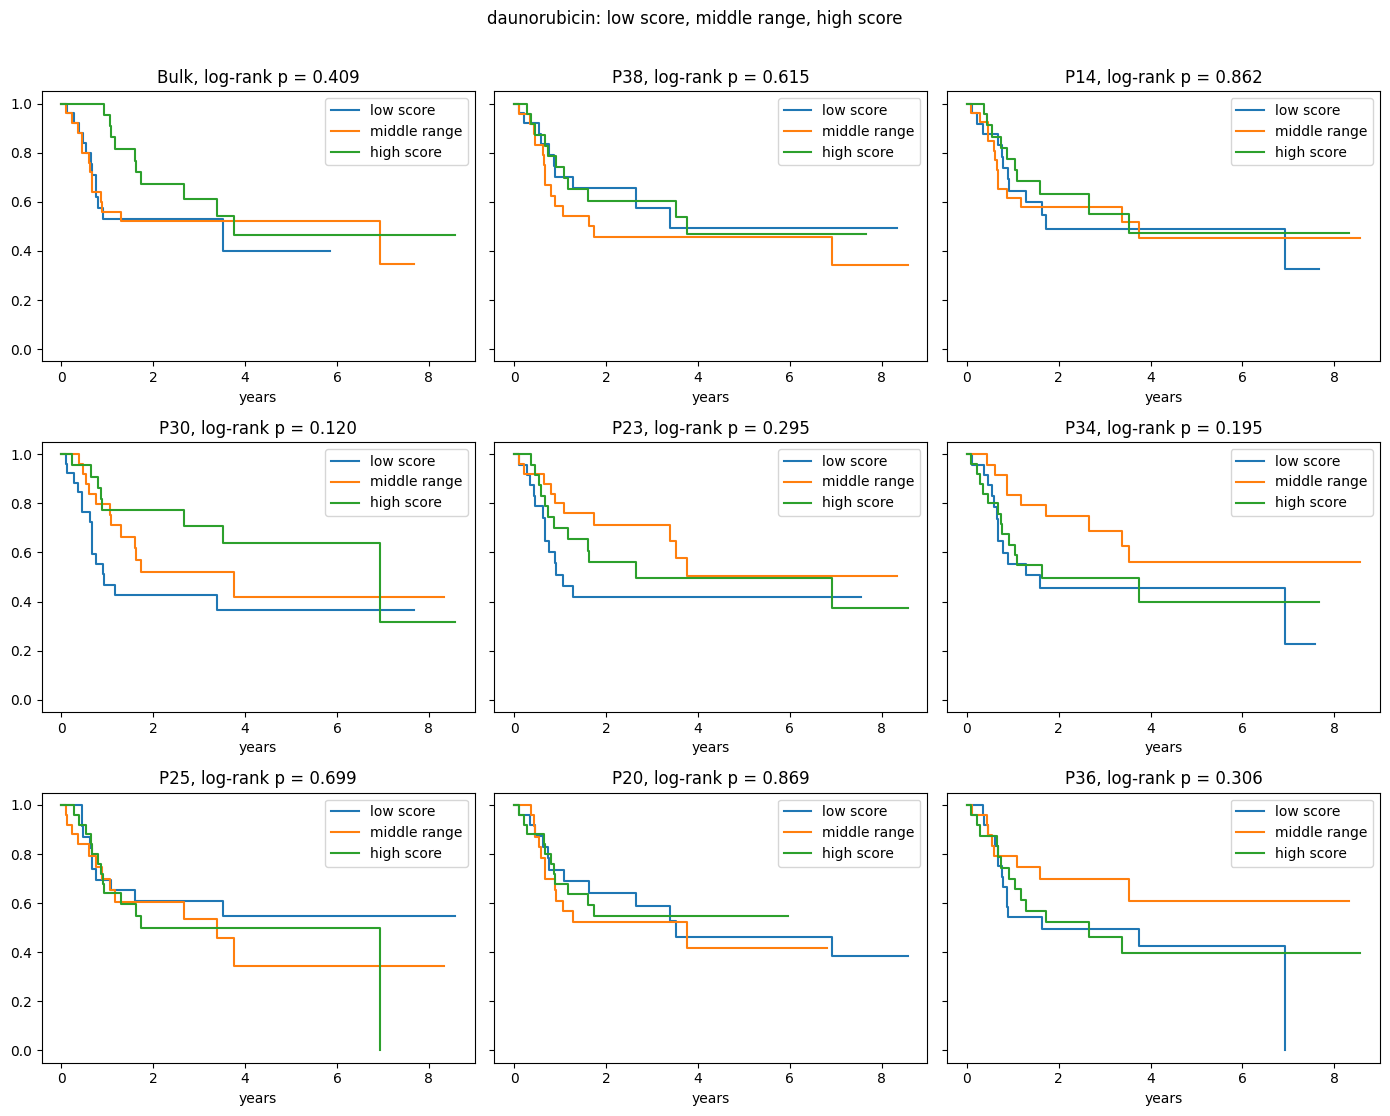

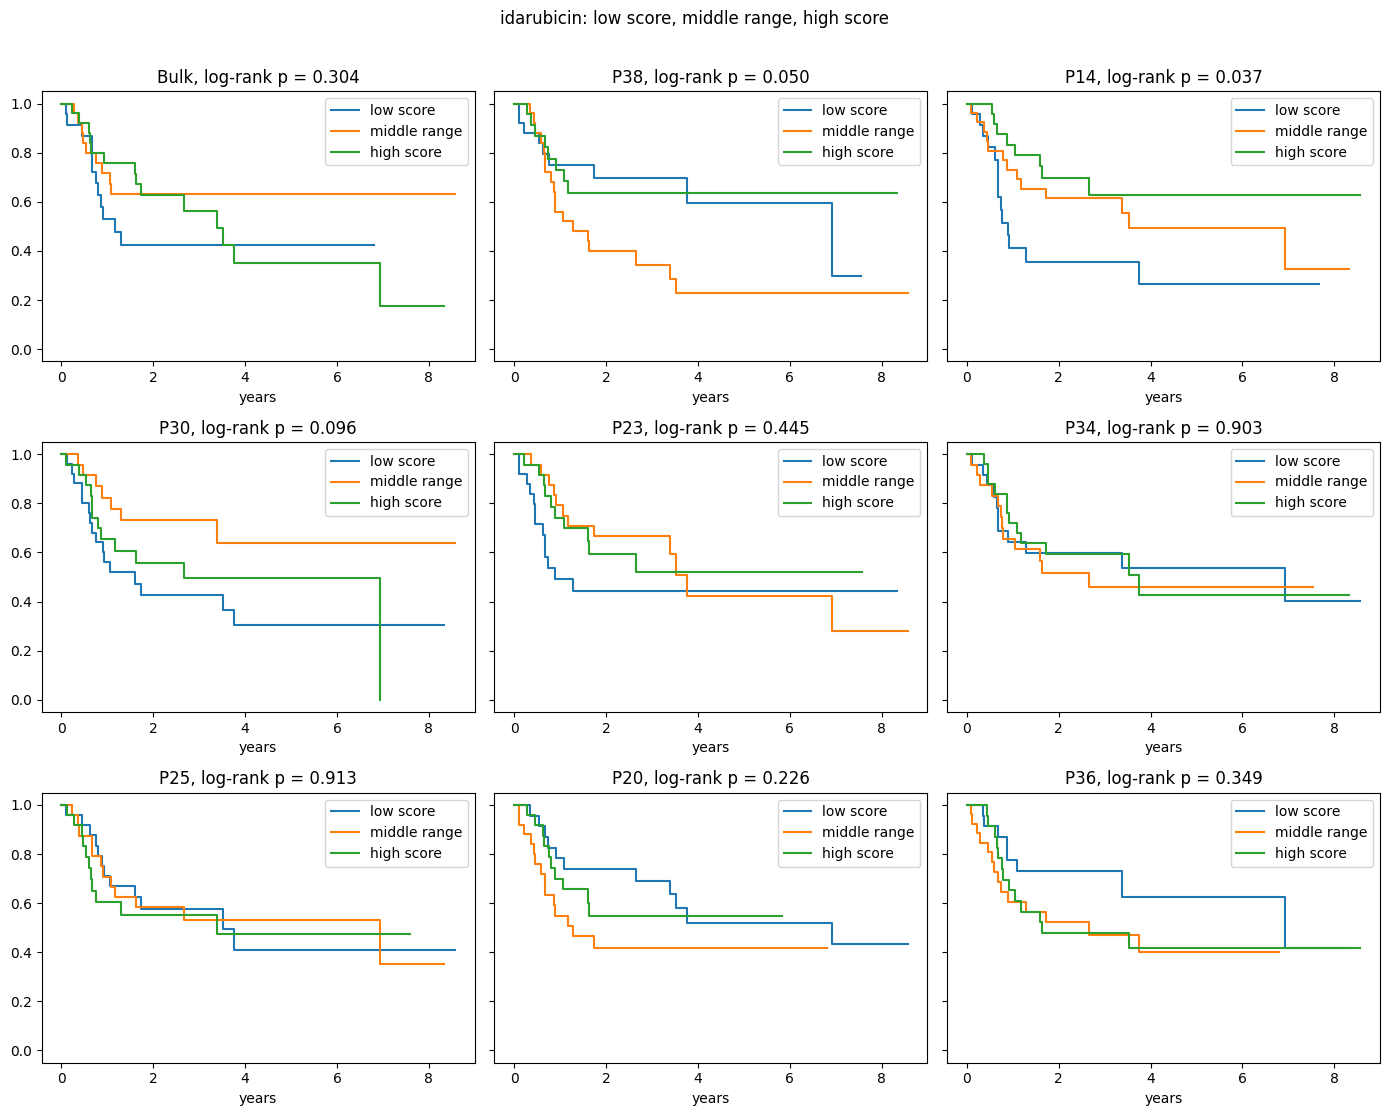

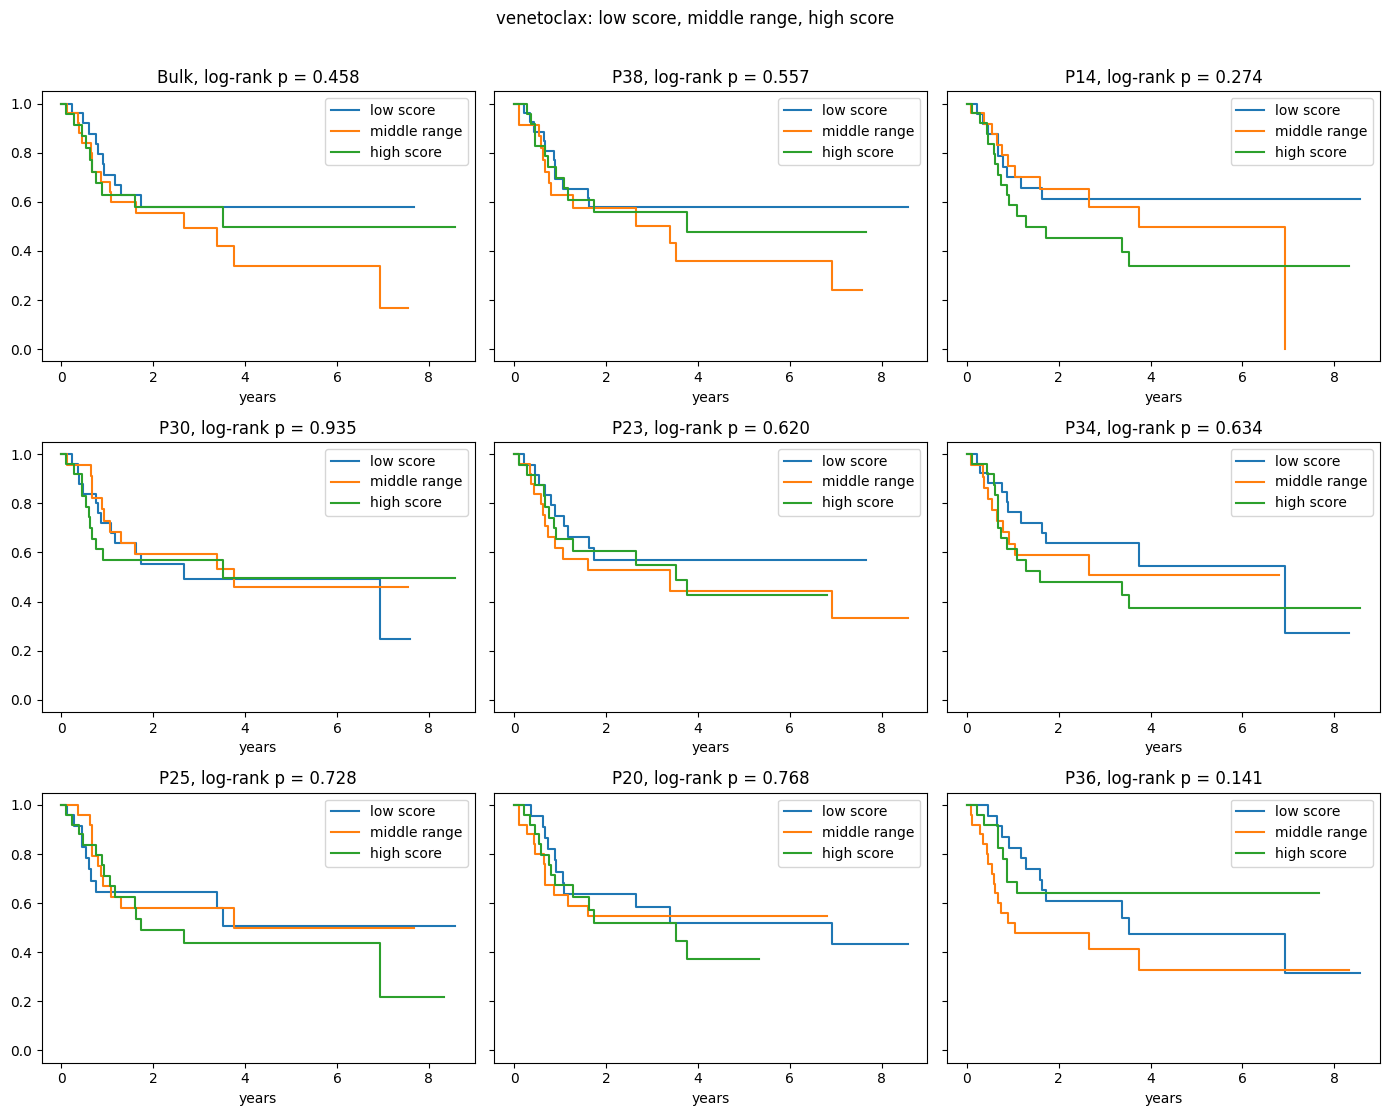

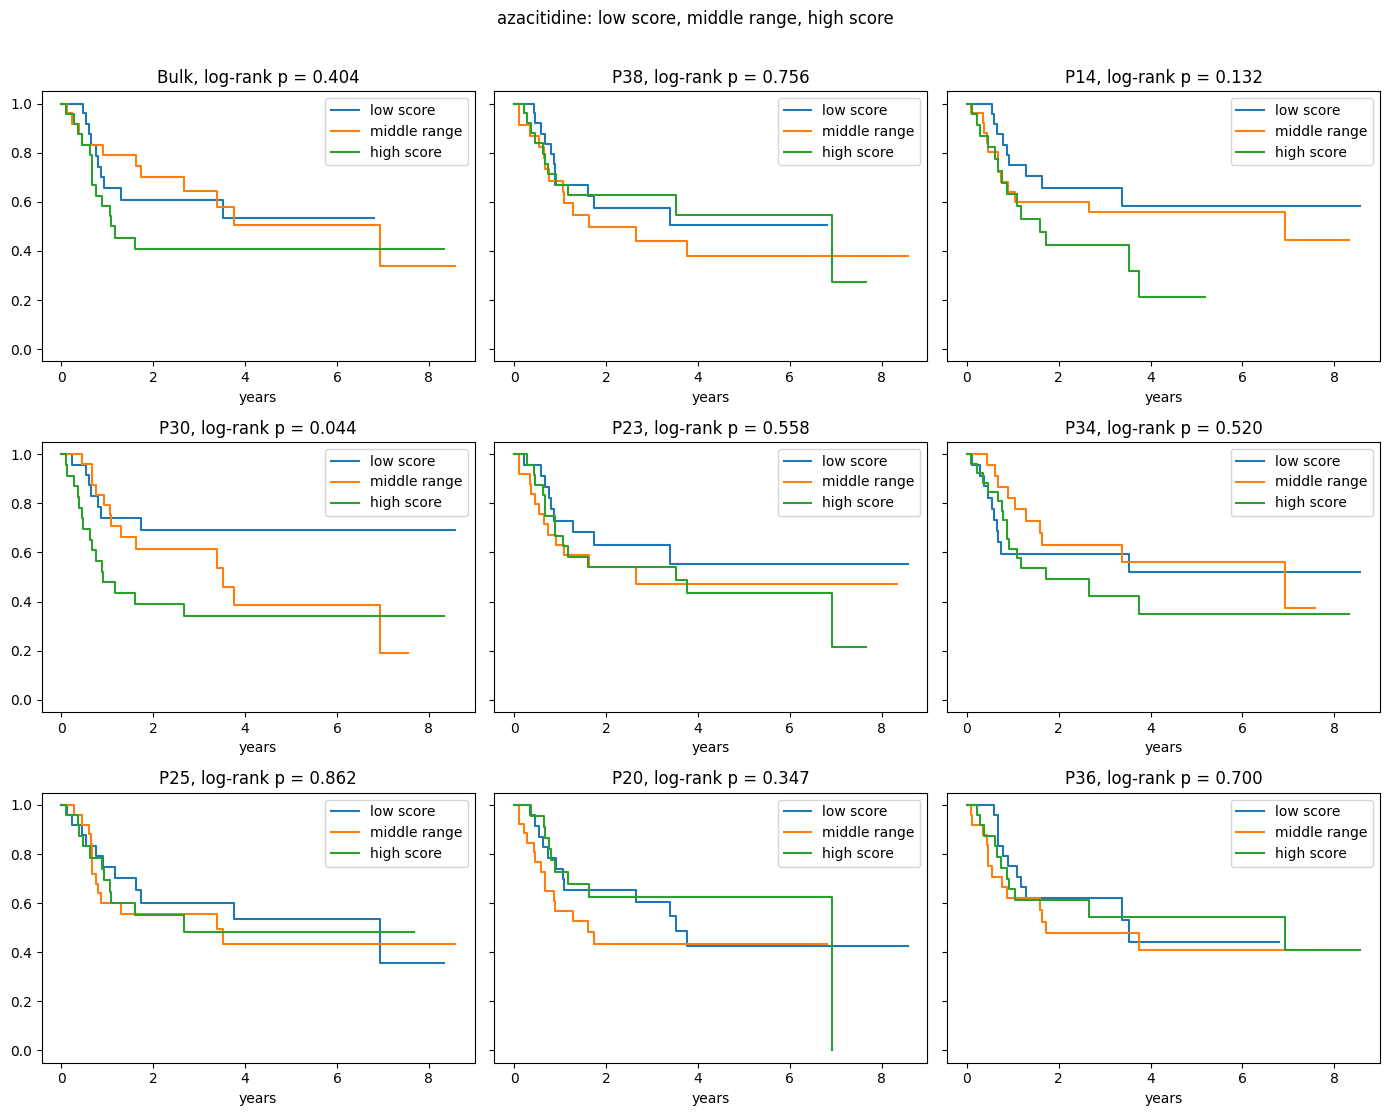

In [11]:
# Kaplan-Meier. Within each panel, patients are split into equal thirds by score.
for drug in drugs:
    fig, axes = plt.subplots(3, 3, figsize=(14, 11), sharey=True)
    axes = axes.flatten()
    for ax, m in zip(axes, scores[drug].columns):
        d = cohort.join(scores[drug][m].rename('score')).dropna(subset=['score']).copy()
        d['band'] = pd.qcut(d.score.rank(method='first'), 3, labels=['low score', 'middle range', 'high score'])
        bands = ['low score', 'middle range', 'high score']
        kmf = KaplanMeierFitter()
        for band in bands:
            sub = d[d.band == band]
            kmf.fit(sub.overallSurvival / 365.25, sub.E, label=band).plot_survival_function(ax=ax, ci_show=False)
        lr = multivariate_logrank_test(d.overallSurvival, d.band, d.E)
        ax.set_title(f'{m}, log-rank p = {lr.p_value:.3f}')
        ax.set_xlabel('years')
    fig.suptitle(drug + ': low score, middle range, high score', y=1.01)
    plt.tight_layout()
    plt.show()

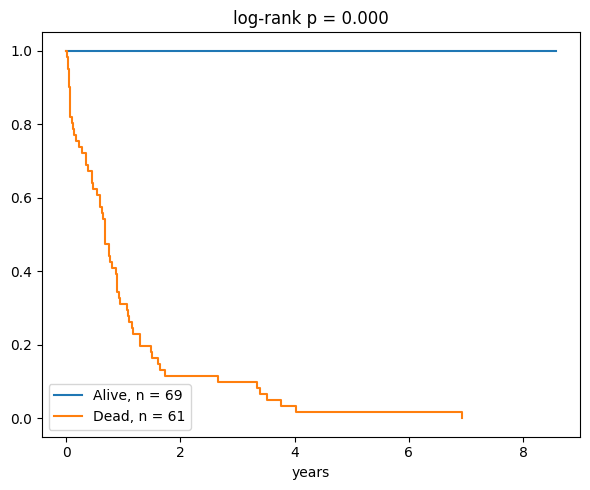

In [12]:
# Survival by vital status.
# Dead and Alive are the survival event itself: every Dead patient is an event and every Alive patient is censored.
d = cohort.dropna(subset=['vitalStatus'])
fig, ax = plt.subplots(figsize=(6, 5))
kmf = KaplanMeierFitter()
for group in ['Alive', 'Dead']:
    sub = d[d.vitalStatus == group]
    kmf.fit(sub.overallSurvival / 365.25, sub.E, label=f'{group}, n = {len(sub)}').plot_survival_function(ax=ax, ci_show=False)
alive = d[d.vitalStatus == 'Alive']
dead = d[d.vitalStatus == 'Dead']
lr = logrank_test(dead.overallSurvival, alive.overallSurvival, dead.E, alive.E)
ax.set_title(f'log-rank p = {lr.p_value:.3f}')
ax.set_xlabel('years')
plt.tight_layout()
plt.show()

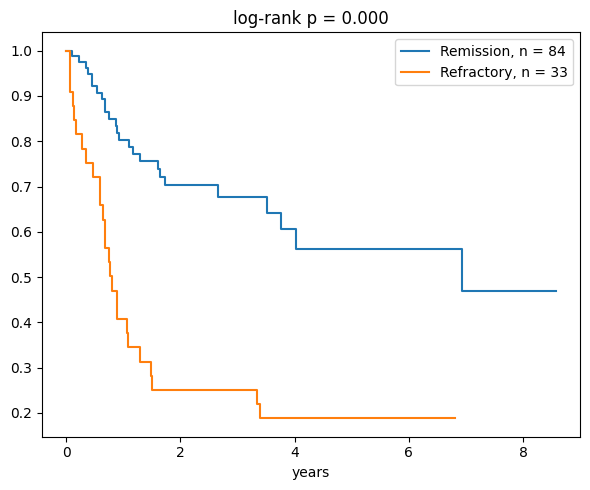

In [13]:
# Survival by response to induction. No TransCell score is used.
d = cohort.dropna(subset=['remission'])
fig, ax = plt.subplots(figsize=(6, 5))
kmf = KaplanMeierFitter()
for group in ['Remission', 'Refractory']:
    sub = d[d.remission == group]
    kmf.fit(sub.overallSurvival / 365.25, sub.E, label=f'{group}, n = {len(sub)}').plot_survival_function(ax=ax, ci_show=False)
rem = d[d.remission == 'Remission']
ref = d[d.remission == 'Refractory']
lr = logrank_test(ref.overallSurvival, rem.overallSurvival, ref.E, rem.E)
ax.set_title(f'log-rank p = {lr.p_value:.3f}')
ax.set_xlabel('years')
plt.tight_layout()
plt.show()

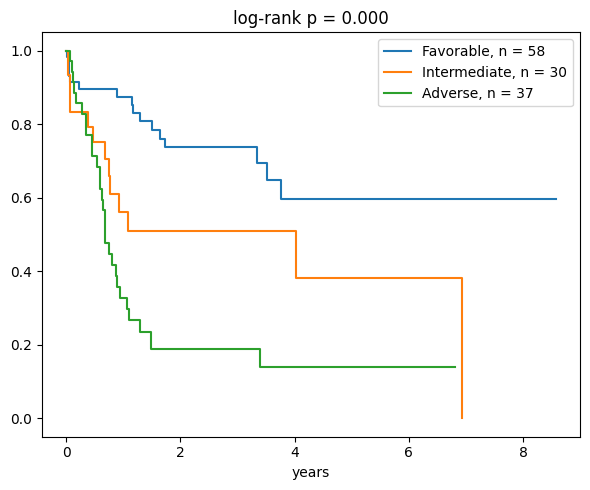

In [14]:
# Survival by ELN2017. No TransCell score is used.
d = cohort.dropna(subset=['eln']).copy()
d['eln_group'] = d.eln.map({0: 'Favorable', 1: 'Intermediate', 2: 'Adverse'})
fig, ax = plt.subplots(figsize=(6, 5))
kmf = KaplanMeierFitter()
for group in ['Favorable', 'Intermediate', 'Adverse']:
    sub = d[d.eln_group == group]
    kmf.fit(sub.overallSurvival / 365.25, sub.E, label=f'{group}, n = {len(sub)}').plot_survival_function(ax=ax, ci_show=False)
lr = multivariate_logrank_test(d.overallSurvival, d.eln_group, d.E)
ax.set_title(f'log-rank p = {lr.p_value:.3f}')
ax.set_xlabel('years')
plt.tight_layout()
plt.show()

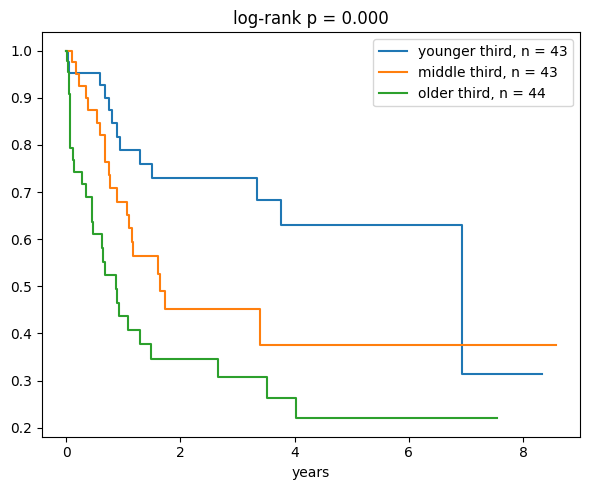

In [15]:
# Survival by age at diagnosis. Equal thirds. No TransCell score is used.
d = cohort.dropna(subset=['ageAtDiagnosis']).copy()
d['age_group'] = pd.qcut(d.ageAtDiagnosis.rank(method='first'), 3, labels=['younger third', 'middle third', 'older third'])
fig, ax = plt.subplots(figsize=(6, 5))
kmf = KaplanMeierFitter()
for group in ['younger third', 'middle third', 'older third']:
    sub = d[d.age_group == group]
    kmf.fit(sub.overallSurvival / 365.25, sub.E, label=f'{group}, n = {len(sub)}').plot_survival_function(ax=ax, ci_show=False)
lr = multivariate_logrank_test(d.overallSurvival, d.age_group, d.E)
ax.set_title(f'log-rank p = {lr.p_value:.3f}')
ax.set_xlabel('years')
plt.tight_layout()
plt.show()

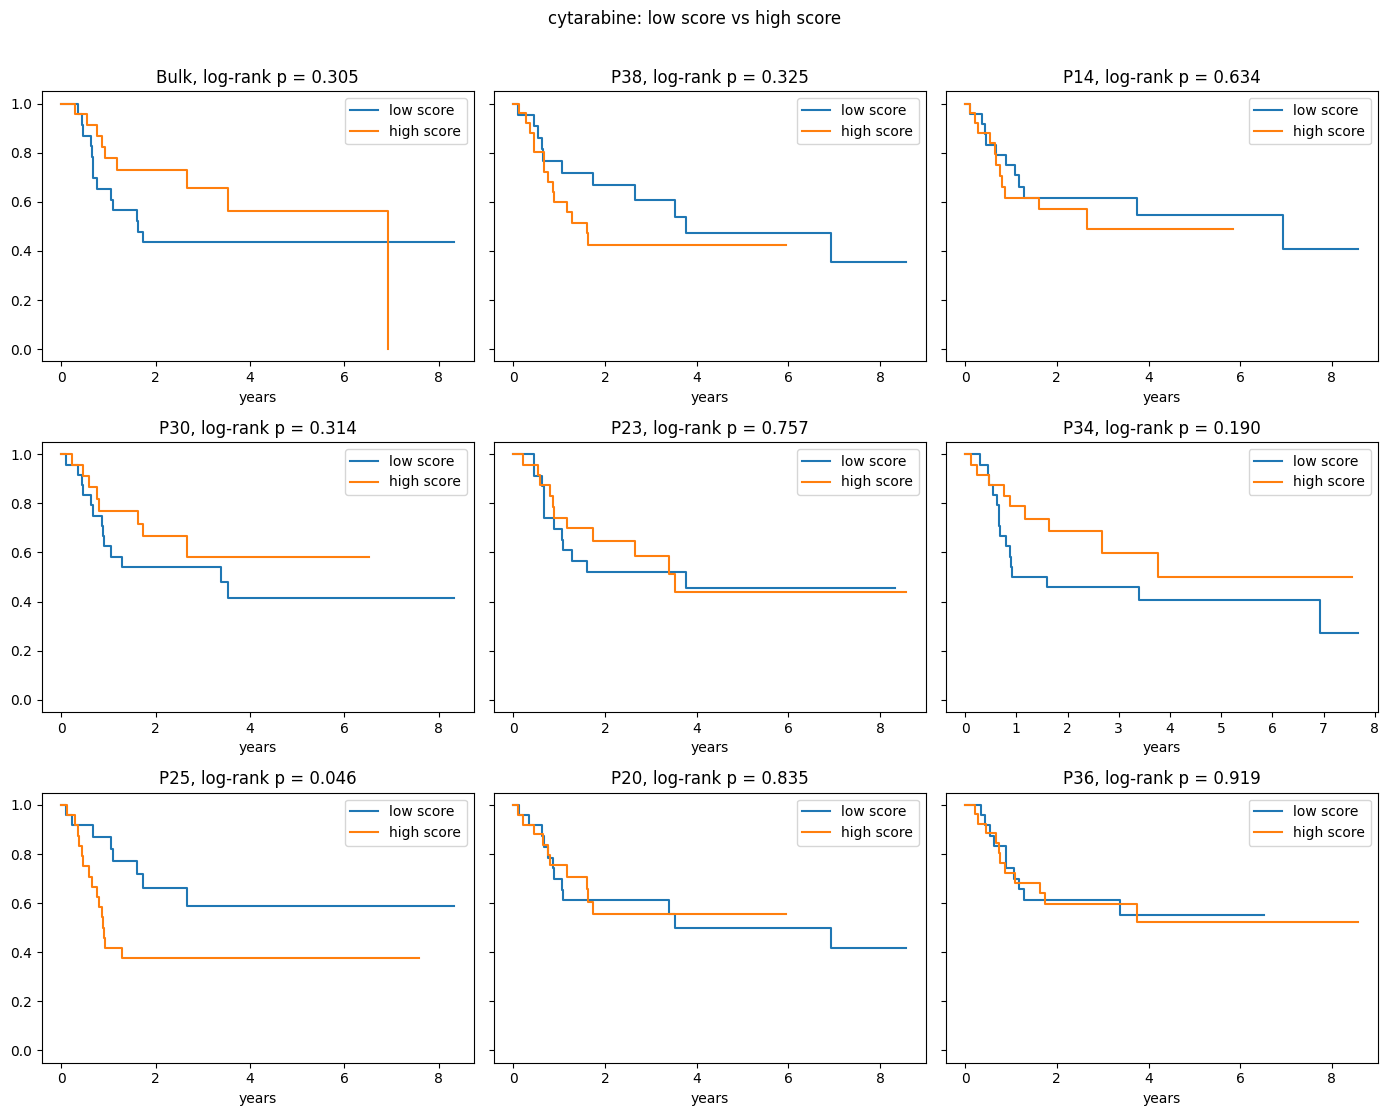

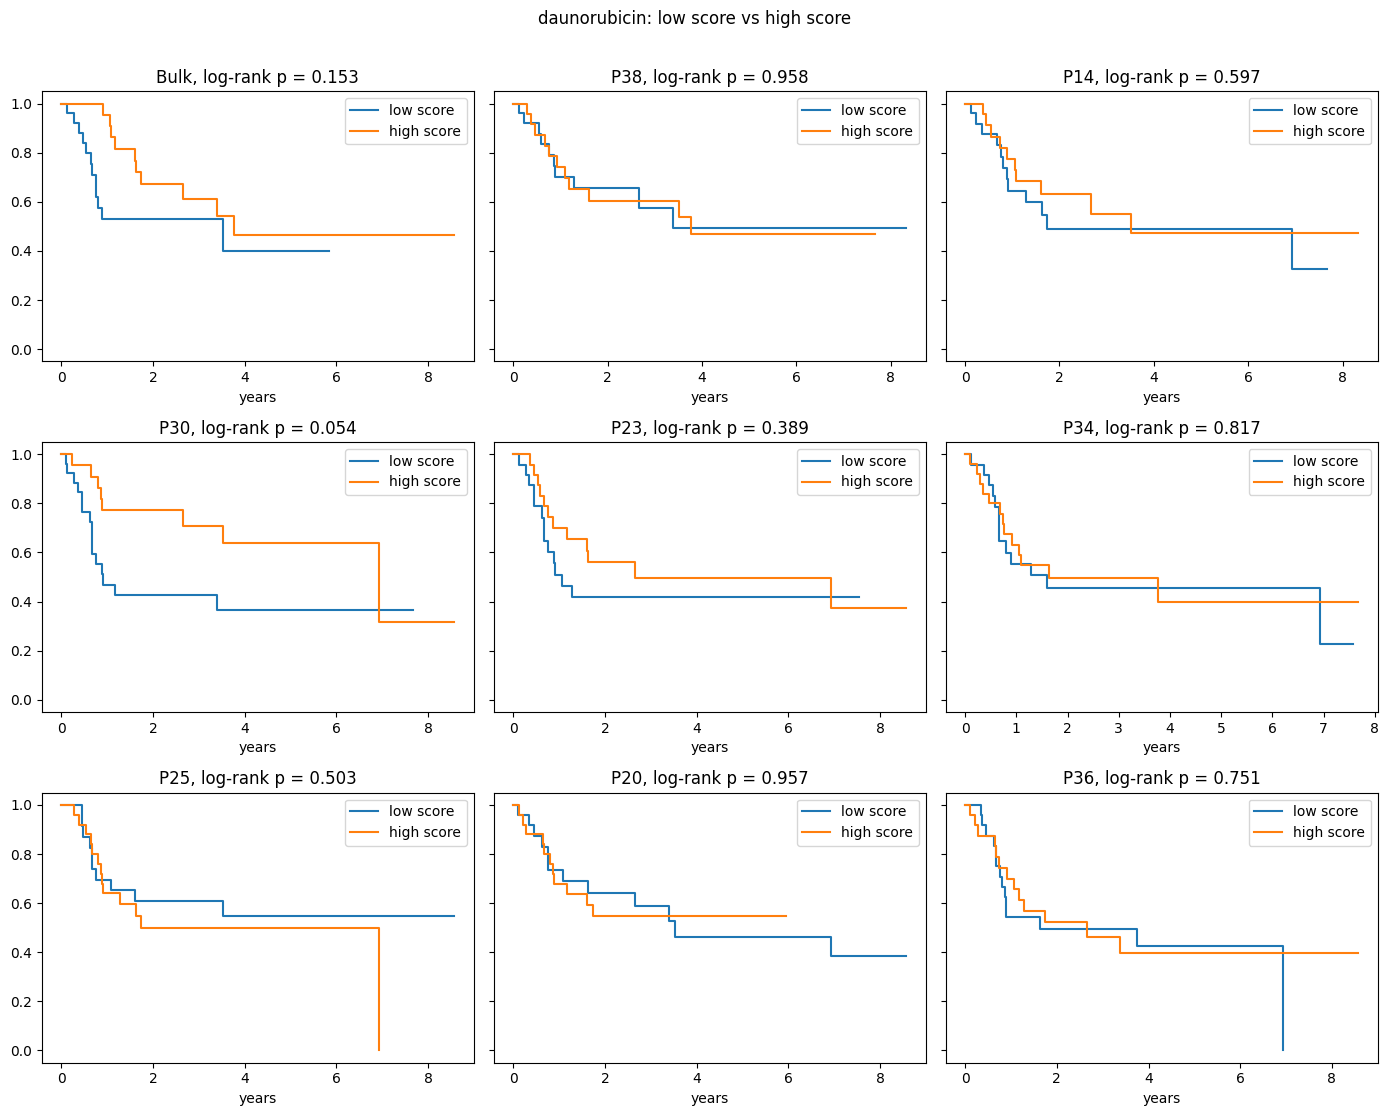

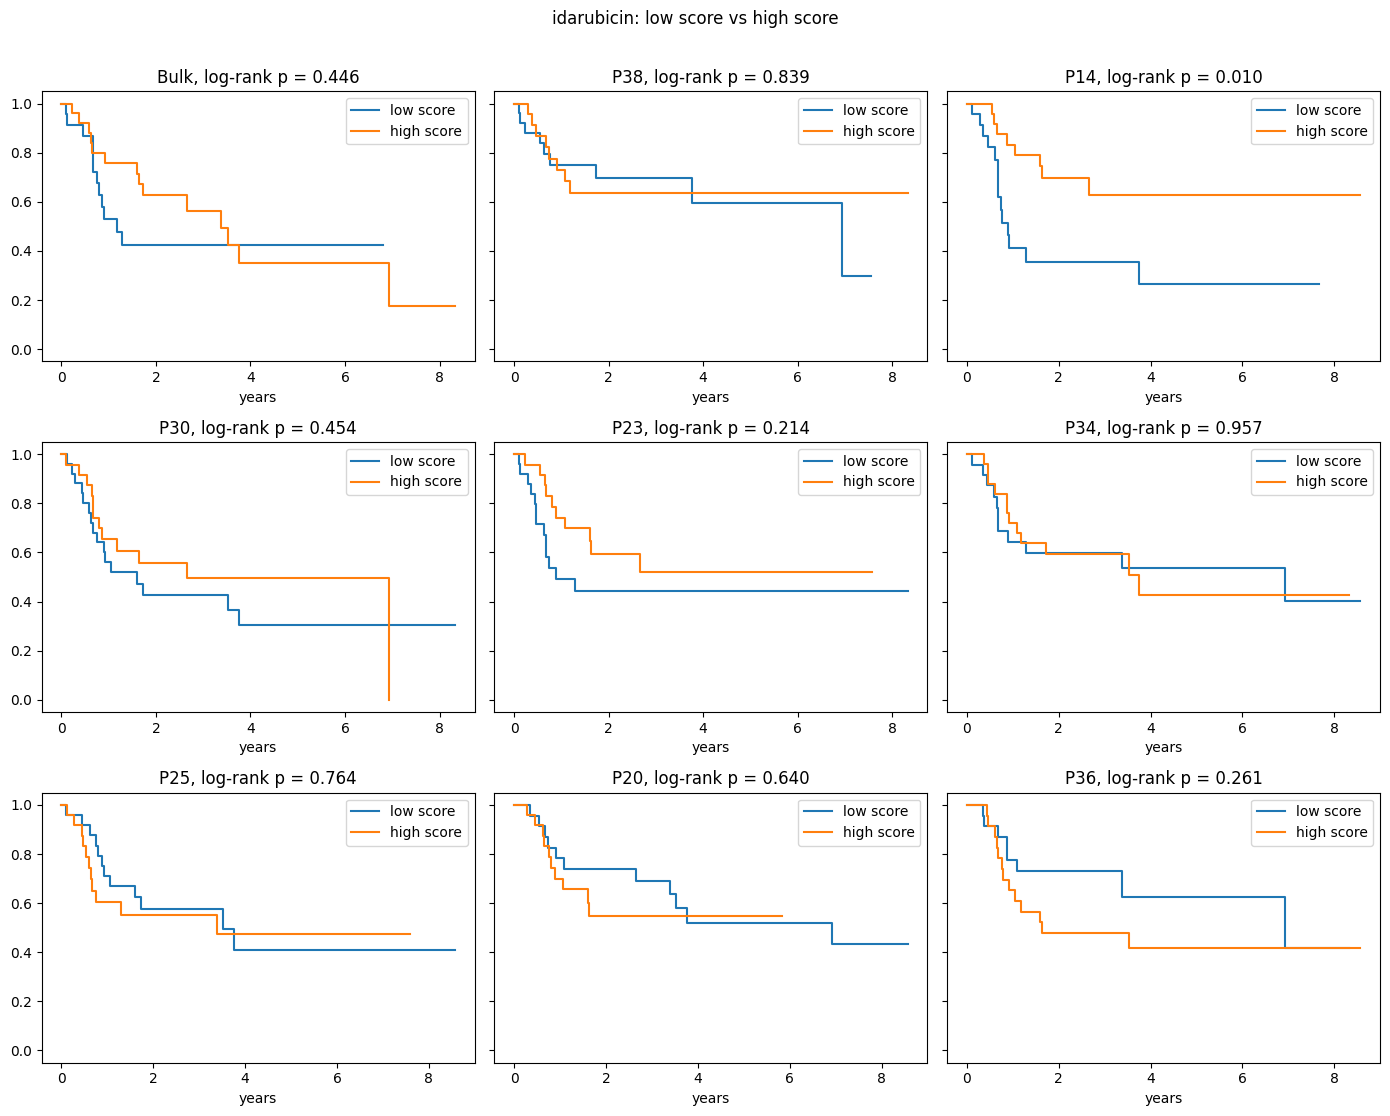

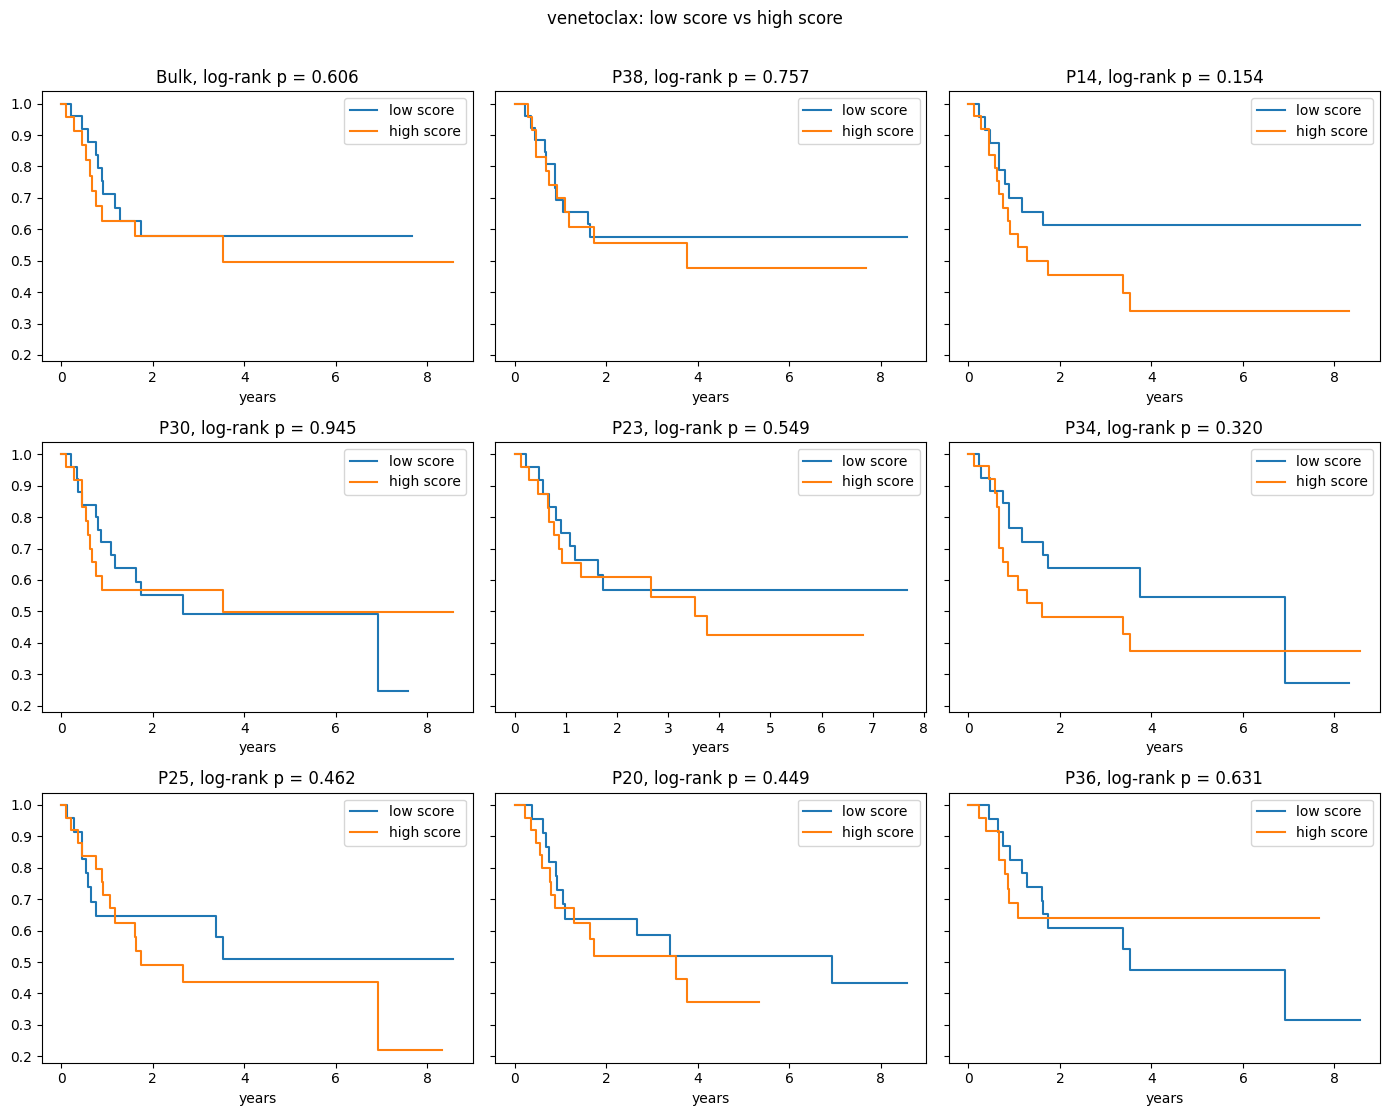

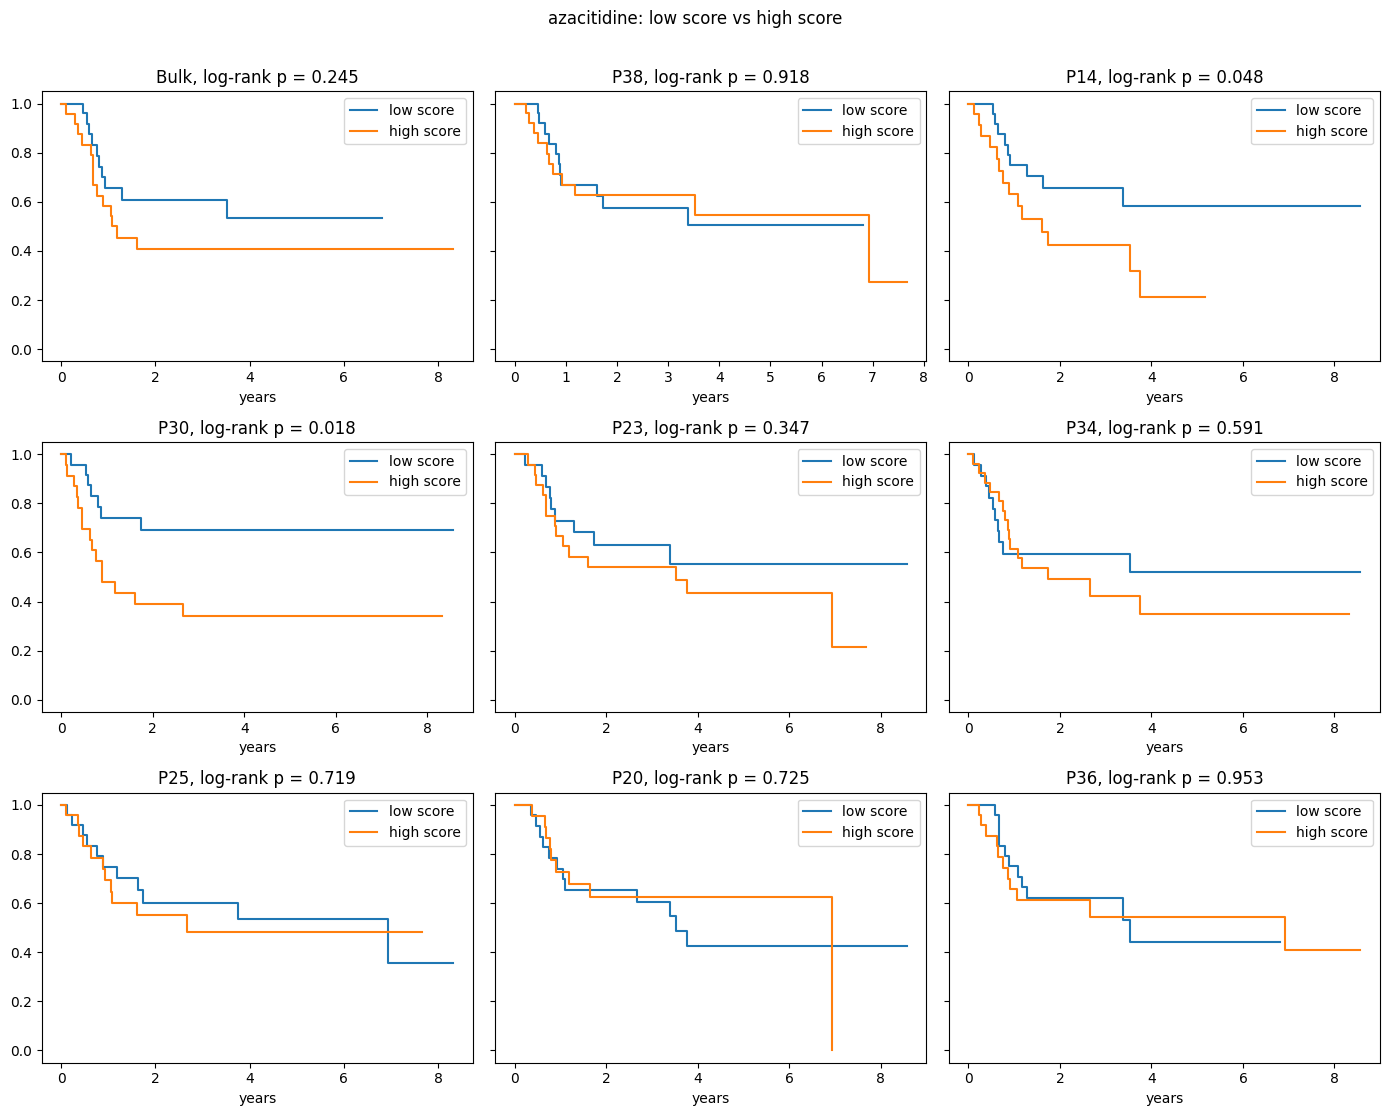

In [16]:
# Kaplan-Meier. Low and high thirds only. The p-value is low versus high.
for drug in drugs:
    fig, axes = plt.subplots(3, 3, figsize=(14, 11), sharey=True)
    axes = axes.flatten()
    for ax, m in zip(axes, scores[drug].columns):
        d = cohort.join(scores[drug][m].rename('score')).dropna(subset=['score']).copy()
        d['band'] = pd.qcut(d.score.rank(method='first'), 3, labels=['low score', 'middle range', 'high score'])
        d = d[d.band != 'middle range']
        kmf = KaplanMeierFitter()
        for band in ['low score', 'high score']:
            sub = d[d.band == band]
            kmf.fit(sub.overallSurvival / 365.25, sub.E, label=band).plot_survival_function(ax=ax, ci_show=False)
        low = d[d.band == 'low score']
        high = d[d.band == 'high score']
        lr = logrank_test(high.overallSurvival, low.overallSurvival, high.E, low.E)
        ax.set_title(f'{m}, log-rank p = {lr.p_value:.3f}')
        ax.set_xlabel('years')
    fig.suptitle(drug + ': low score vs high score', y=1.01)
    plt.tight_layout()
    plt.show()

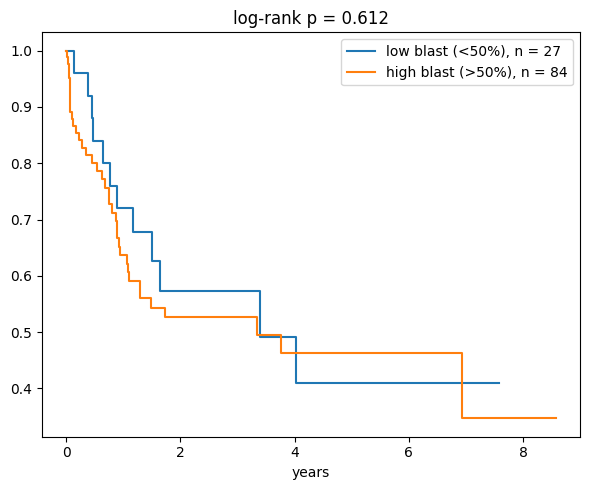

In [17]:
# Survival by bone-marrow blast percentage. No TransCell score is used.
d = cohort.dropna(subset=['blast_group'])
fig, ax = plt.subplots(figsize=(6, 5))
kmf = KaplanMeierFitter()
for group in ['low blast (<50%)', 'high blast (>50%)']:
    sub = d[d.blast_group == group]
    kmf.fit(sub.overallSurvival / 365.25, sub.E, label=f'{group}, n = {len(sub)}').plot_survival_function(ax=ax, ci_show=False)
low = d[d.blast_group == 'low blast (<50%)']
high = d[d.blast_group == 'high blast (>50%)']
lr = logrank_test(high.overallSurvival, low.overallSurvival, high.E, low.E)
ax.set_title(f'log-rank p = {lr.p_value:.3f}')
ax.set_xlabel('years')
plt.tight_layout()
plt.show()

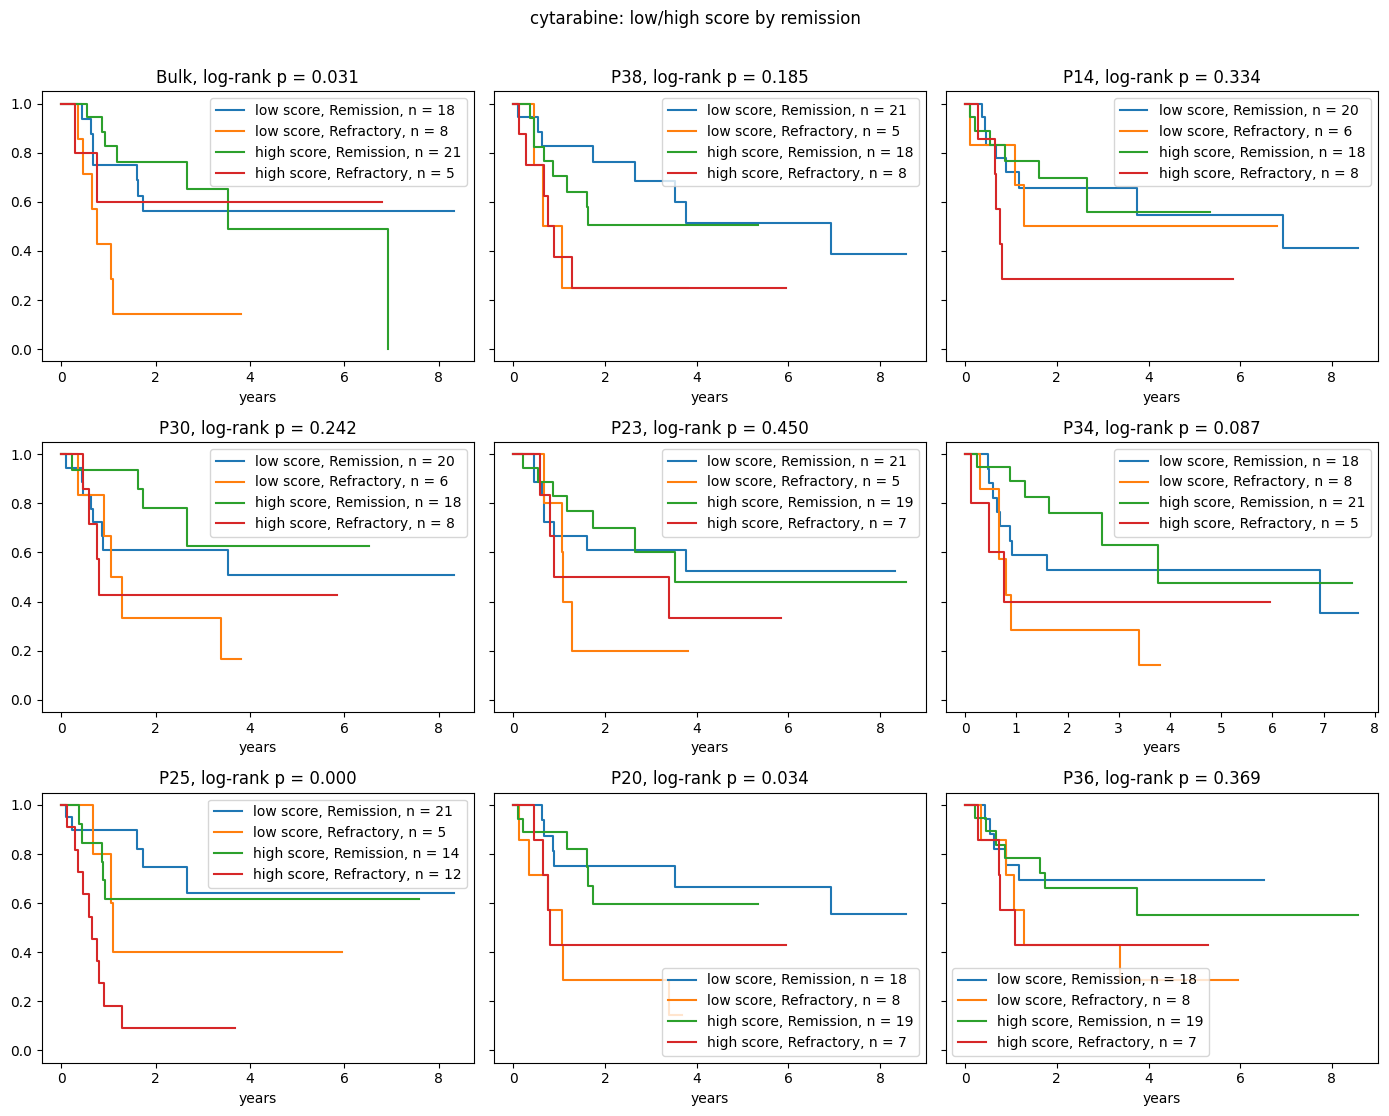

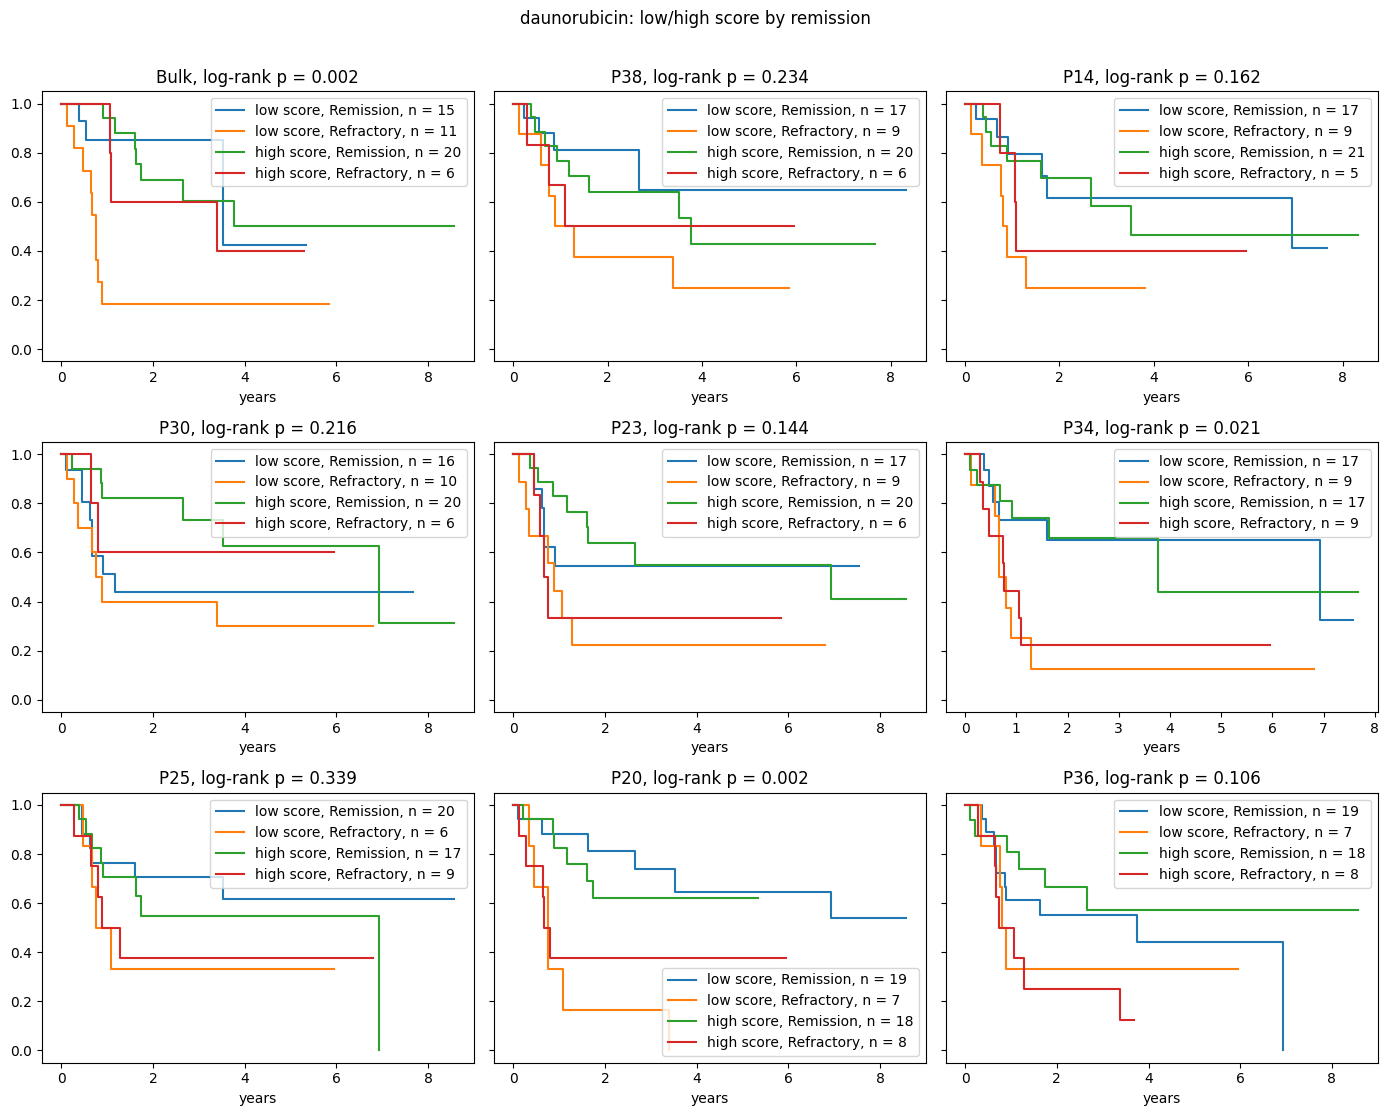

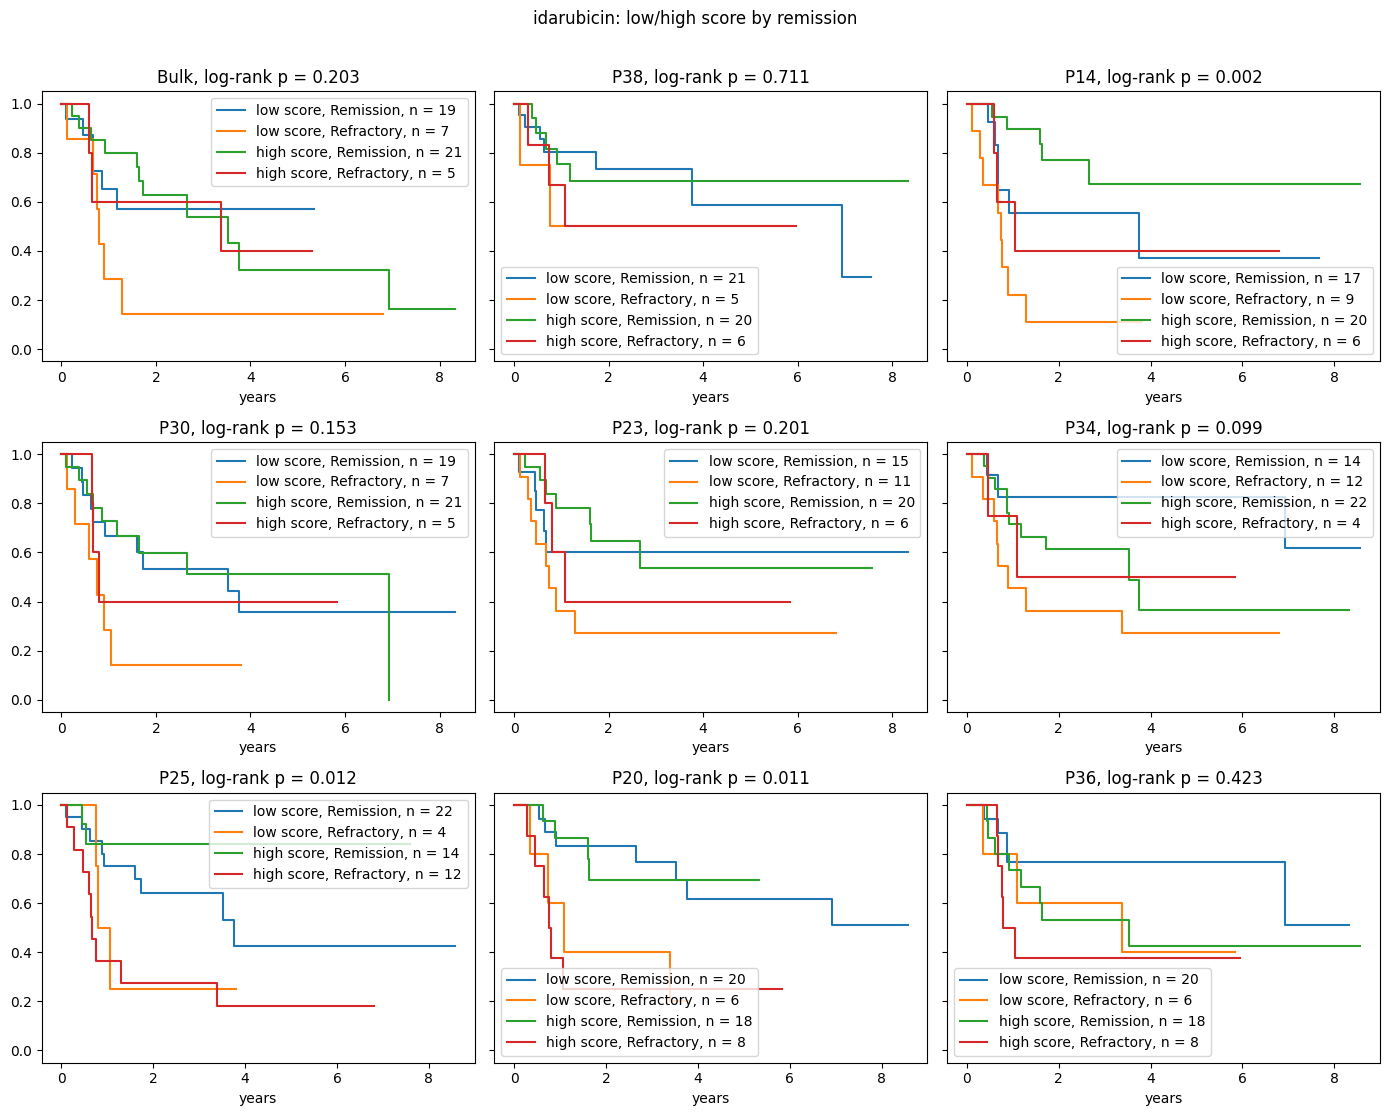

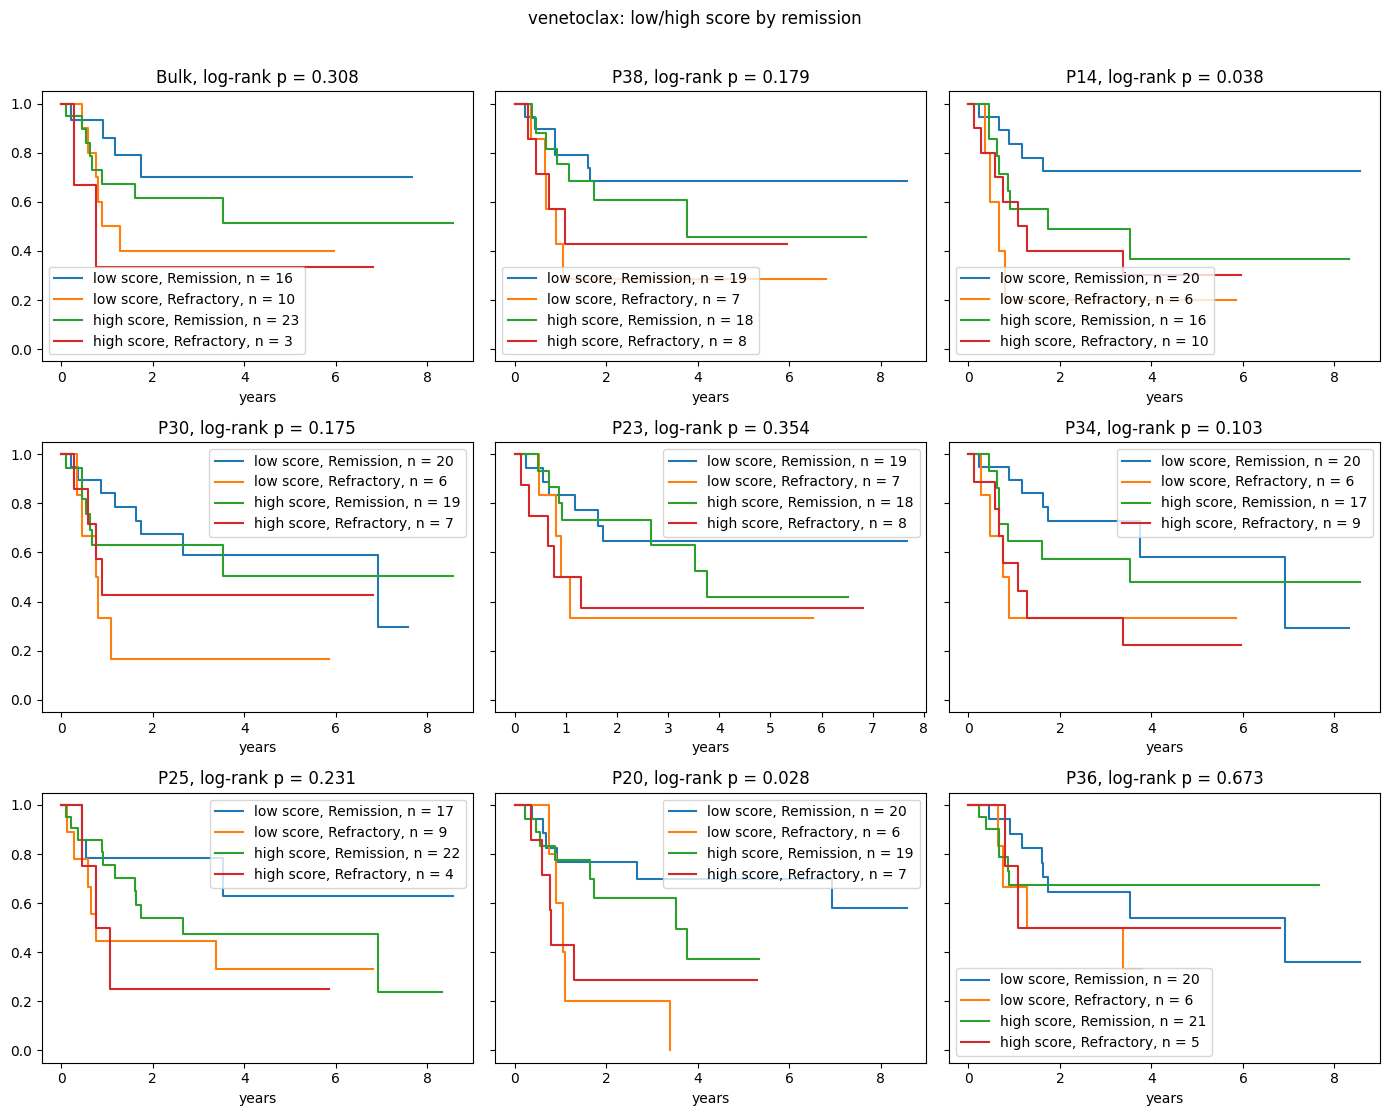

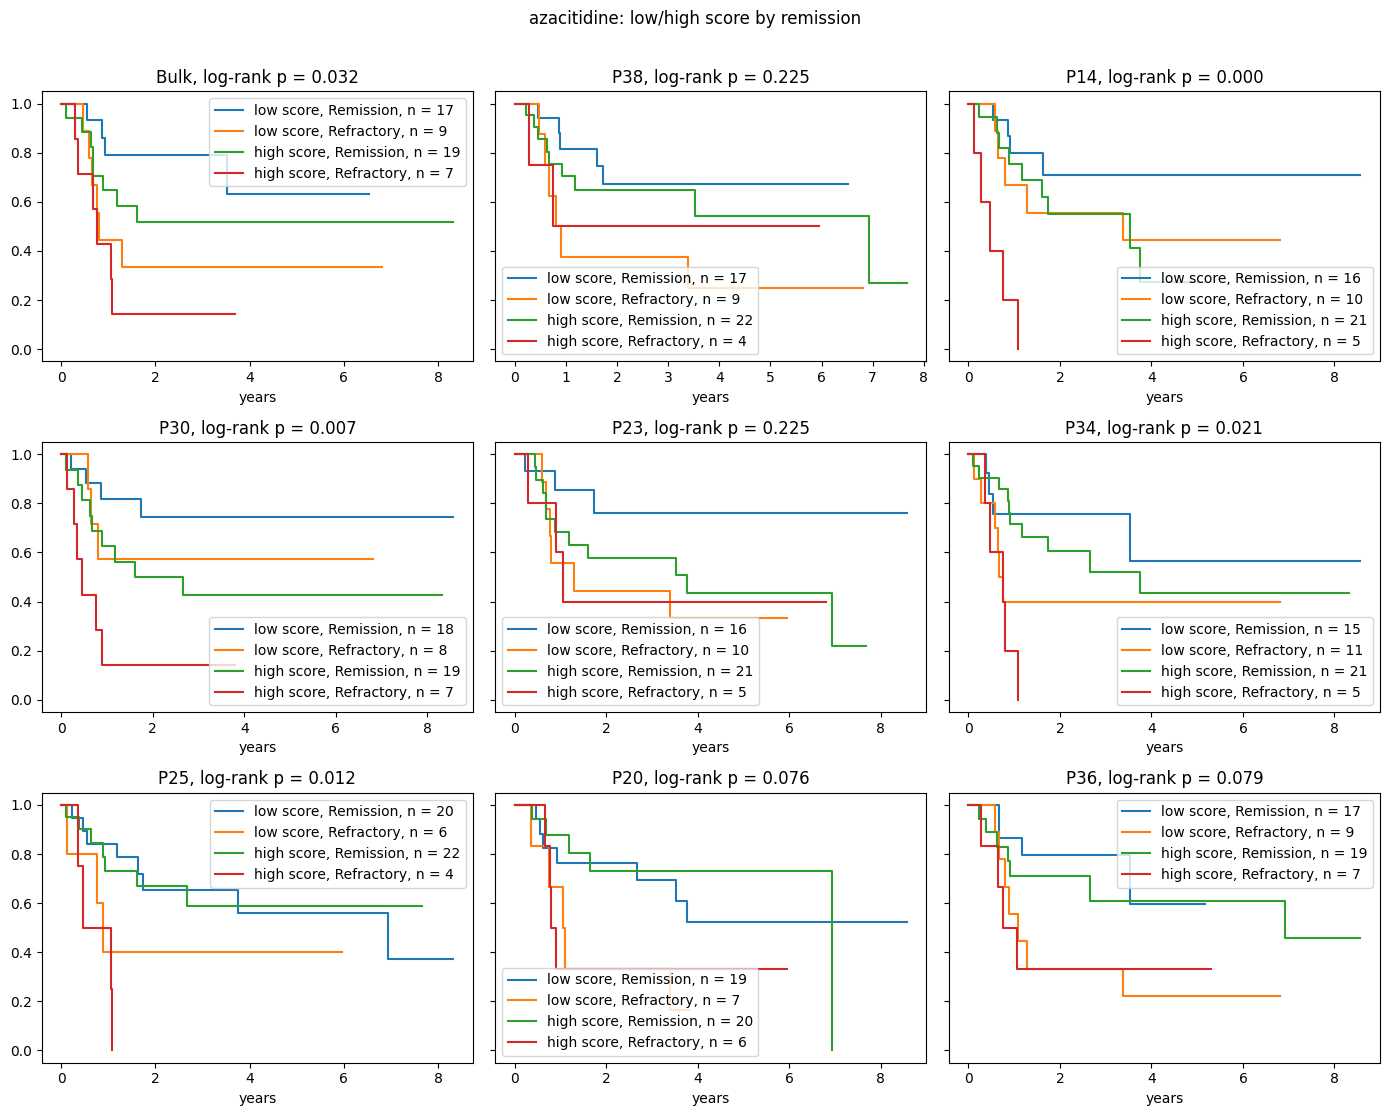

In [18]:
# Kaplan-Meier. Low and high score thirds, split by remission. Four curves per panel.
for drug in drugs:
    fig, axes = plt.subplots(3, 3, figsize=(14, 11), sharey=True)
    axes = axes.flatten()
    for ax, m in zip(axes, scores[drug].columns):
        d = cohort.join(scores[drug][m].rename('score')).dropna(subset=['score']).copy()
        d['band'] = pd.qcut(d.score.rank(method='first'), 3, labels=['low score', 'middle range', 'high score'])
        d = d[d.band != 'middle range'].dropna(subset=['remission'])
        d['group'] = d.band.astype(str) + ', ' + d.remission.astype(str)
        groups = ['low score, Remission', 'low score, Refractory', 'high score, Remission', 'high score, Refractory']
        kmf = KaplanMeierFitter()
        for group in groups:
            sub = d[d.group == group]
            if len(sub) == 0:
                continue
            kmf.fit(sub.overallSurvival / 365.25, sub.E, label=f'{group}, n = {len(sub)}').plot_survival_function(ax=ax, ci_show=False)
        lr = multivariate_logrank_test(d.overallSurvival, d.group, d.E)
        ax.set_title(f'{m}, log-rank p = {lr.p_value:.3f}')
        ax.set_xlabel('years')
    fig.suptitle(drug + ': low/high score by remission', y=1.01)
    plt.tight_layout()
    plt.show()

cytarabine 57
daunorubicin no AUC
idarubicin no AUC
venetoclax 69
azacitidine 67


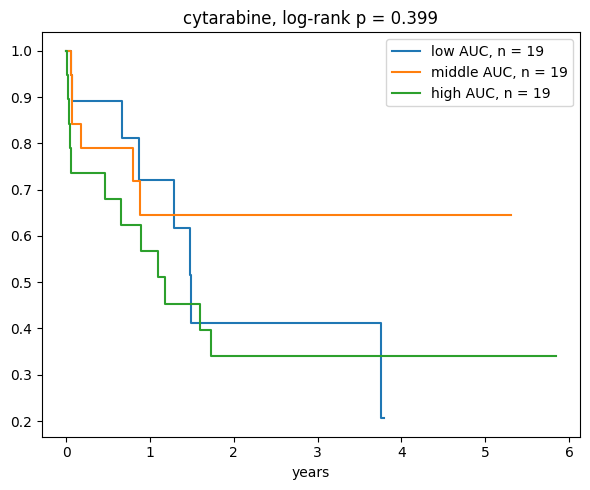

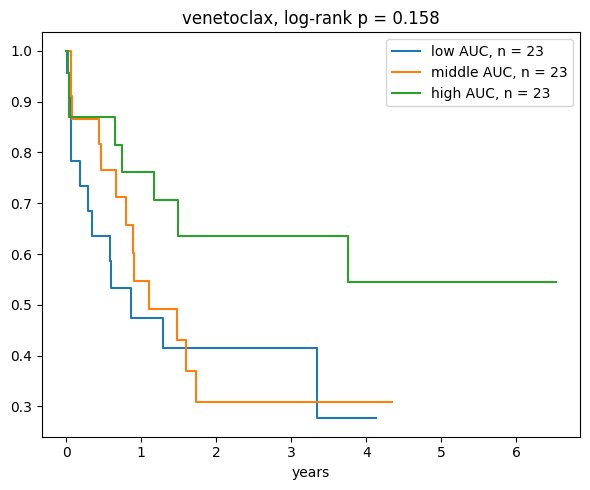

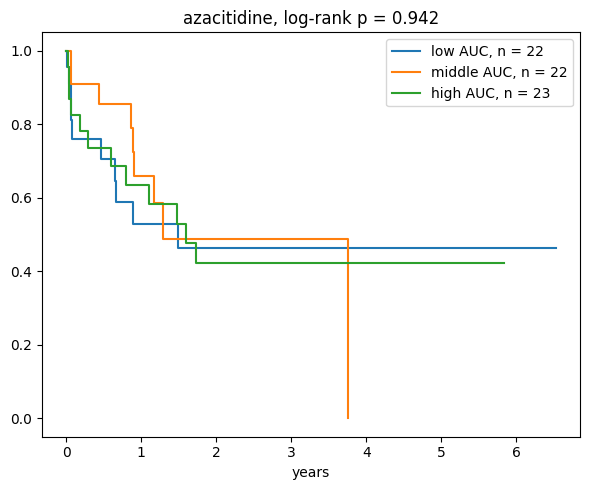

In [19]:
# Ex vivo AUC vs survival. Higher AUC means less sensitive.
# Daunorubicin and idarubicin are not in the AUC file.
auc_file = pd.read_csv(DRUG_AUC, usecols=['dbgap_subject_id', 'inhibitor', 'auc'])
auc_name = {'cytarabine': 'Cytarabine', 'daunorubicin': 'Daunorubicin', 'idarubicin': 'Idarubicin', 'venetoclax': 'Venetoclax', 'azacitidine':'Azacytidine'}
auc = {}
for drug in drugs:
    one = auc_file[auc_file.inhibitor == auc_name[drug]]
    if len(one) == 0:
        print(drug, 'no AUC')
        continue
    auc[drug] = one.groupby('dbgap_subject_id').auc.mean().reindex(cohort.index)
    print(drug, int(auc[drug].notna().sum()))

# Kaplan-Meier. Equal thirds by AUC.
for drug in auc:
    d = cohort.join(auc[drug].rename('auc')).dropna(subset=['auc']).copy()
    d['band'] = pd.qcut(d.auc.rank(method='first'), 3, labels=['low AUC', 'middle AUC', 'high AUC'])
    fig, ax = plt.subplots(figsize=(6, 5))
    kmf = KaplanMeierFitter()
    for band in ['low AUC', 'middle AUC', 'high AUC']:
        sub = d[d.band == band]
        kmf.fit(sub.overallSurvival / 365.25, sub.E, label=f'{band}, n = {len(sub)}').plot_survival_function(ax=ax, ci_show=False)
    lr = multivariate_logrank_test(d.overallSurvival, d.band, d.E)
    ax.set_title(f'{drug}, log-rank p = {lr.p_value:.3f}')
    ax.set_xlabel('years')
    plt.tight_layout()
    plt.show()

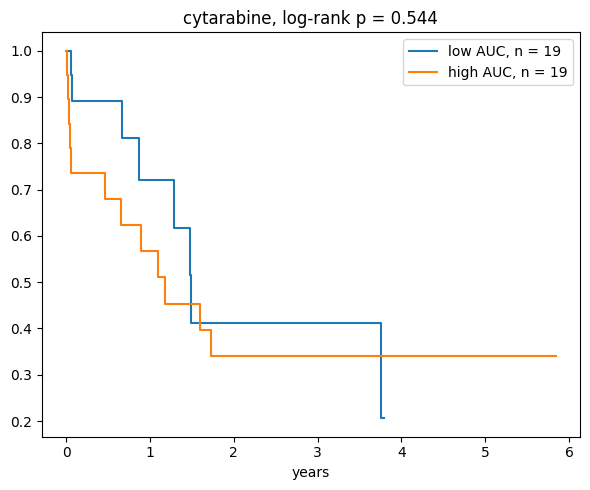

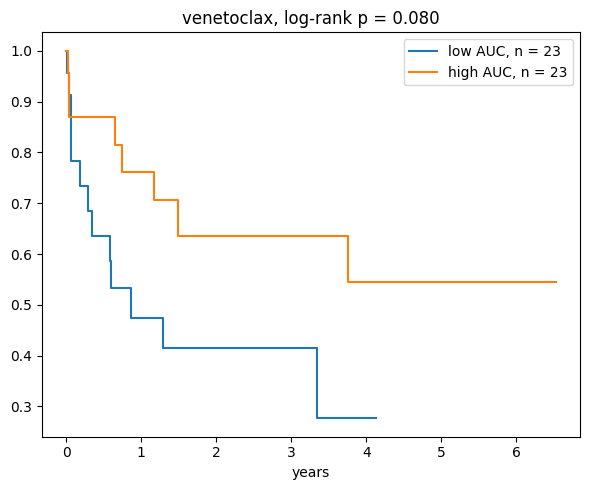

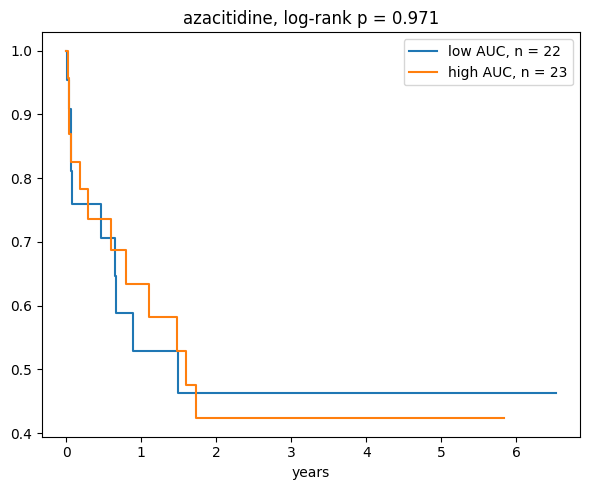

In [20]:
# Kaplan-Meier. Low and high AUC thirds only. The p-value is low versus high.
for drug in auc:
    d = cohort.join(auc[drug].rename('auc')).dropna(subset=['auc']).copy()
    d['band'] = pd.qcut(d.auc.rank(method='first'), 3, labels=['low AUC', 'middle AUC', 'high AUC'])
    d = d[d.band != 'middle AUC']
    fig, ax = plt.subplots(figsize=(6, 5))
    kmf = KaplanMeierFitter()
    for band in ['low AUC', 'high AUC']:
        sub = d[d.band == band]
        kmf.fit(sub.overallSurvival / 365.25, sub.E, label=f'{band}, n = {len(sub)}').plot_survival_function(ax=ax, ci_show=False)
    low = d[d.band == 'low AUC']
    high = d[d.band == 'high AUC']
    lr = logrank_test(high.overallSurvival, low.overallSurvival, high.E, low.E)
    ax.set_title(f'{drug}, log-rank p = {lr.p_value:.3f}')
    ax.set_xlabel('years')
    plt.tight_layout()
    plt.show()

In [21]:
# Summary statistics for KM log-rank tests and ex vivo AUC vs survival
print('--- Clinical & blast log-rank p-values ---')
rem = cohort[cohort.remission == 'Remission']
ref = cohort[cohort.remission == 'Refractory']
print('Remission vs Refractory p =', round(logrank_test(ref.overallSurvival, rem.overallSurvival, ref.E, rem.E).p_value, 4))

d_eln = cohort.dropna(subset=['eln'])
print('ELN2017 (3 groups) p =', round(multivariate_logrank_test(d_eln.overallSurvival, d_eln.eln, d_eln.E).p_value, 4))

d_age = cohort.dropna(subset=['ageAtDiagnosis']).copy()
d_age['g'] = pd.qcut(d_age.ageAtDiagnosis.rank(method='first'), 3, labels=['y', 'm', 'o'])
print('Age tertiles p =', round(multivariate_logrank_test(d_age.overallSurvival, d_age.g, d_age.E).p_value, 4))

d_bl = cohort.dropna(subset=['blast_group'])
print('Blast <50% vs >50% p =', round(logrank_test(
    d_bl[d_bl.blast_group == 'high blast (>50%)'].overallSurvival,
    d_bl[d_bl.blast_group == 'low blast (<50%)'].overallSurvival,
    d_bl[d_bl.blast_group == 'high blast (>50%)'].E,
    d_bl[d_bl.blast_group == 'low blast (<50%)'].E).p_value, 4))

print('\n--- Ex vivo AUC vs survival (7+3 cohort) ---')
auc_rows = []
for drug in auc:
    d = cohort.join(auc[drug].rename('auc')).dropna(subset=['auc']).copy()
    d['band'] = pd.qcut(d.auc.rank(method='first'), 3, labels=['low AUC', 'middle AUC', 'high AUC'])
    lr3 = multivariate_logrank_test(d.overallSurvival, d.band, d.E).p_value
    low = d[d.band == 'low AUC']
    high = d[d.band == 'high AUC']
    lr2 = logrank_test(high.overallSurvival, low.overallSurvival, high.E, low.E).p_value
    fit = d.dropna(subset=['ageAtDiagnosis', 'eln']).copy()
    fit['z'] = (fit.auc - fit.auc.mean()) / fit.auc.std()
    cph = CoxPHFitter().fit(fit[['overallSurvival', 'E', 'z', 'ageAtDiagnosis', 'eln']], 'overallSurvival', 'E')
    s = cph.summary.loc['z']
    auc_rows.append([drug, len(d), int(d.E.sum()), lr3, lr2, len(fit), s['exp(coef)'], s['p']])
print(DataFrame(auc_rows, columns=['drug', 'n_km', 'deaths', 'logrank_3grp_p', 'logrank_low_high_p', 'n_cox', 'HR_per_SD', 'cox_p']).round(3).to_string(index=False))

print('\n--- TransCell score KM log-rank p-values (low vs high third) ---')
km_rows = []
for drug in drugs:
    for m in scores[drug].columns:
        d = cohort.join(scores[drug][m].rename('score')).dropna(subset=['score']).copy()
        d['band'] = pd.qcut(d.score.rank(method='first'), 3, labels=['low score', 'middle range', 'high score'])
        lr3 = multivariate_logrank_test(d.overallSurvival, d.band, d.E).p_value
        low = d[d.band == 'low score']
        high = d[d.band == 'high score']
        lr2 = logrank_test(high.overallSurvival, low.overallSurvival, high.E, low.E).p_value
        km_rows.append([drug, m, len(d), lr3, lr2])
print(DataFrame(km_rows, columns=['drug', 'method', 'n', 'logrank_3grp_p', 'logrank_low_high_p']).round(3).to_string(index=False))

--- Clinical & blast log-rank p-values ---
Remission vs Refractory p = 0.0
ELN2017 (3 groups) p = 0.0
Age tertiles p = 0.0004
Blast <50% vs >50% p = 0.6117

--- Ex vivo AUC vs survival (7+3 cohort) ---
       drug  n_km  deaths  logrank_3grp_p  logrank_low_high_p  n_cox  HR_per_SD  cox_p
 cytarabine    57      26           0.399               0.544     56      1.130  0.600
 venetoclax    69      34           0.158               0.080     67      0.688  0.041
azacitidine    67      31           0.942               0.971     64      0.967  0.877

--- TransCell score KM log-rank p-values (low vs high third) ---
        drug method  n  logrank_3grp_p  logrank_low_high_p
  cytarabine   Bulk 78           0.543               0.305
  cytarabine    P38 78           0.417               0.325
  cytarabine    P14 78           0.816               0.634
  cytarabine    P30 78           0.541               0.314
  cytarabine    P23 78           0.868               0.757
  cytarabine    P34 78        